# Tiamat
## Prevendo a biodegradabilidade de substâncias químicas a partir de descritores moleculares
-------------------------------------------------------------------------------------------------------------------
**Autor:** Luis Navarro Erbetta (2610080)

**Disciplina:** Aprendizado de Máquina

**Instituição:** Ilum Escola de Ciência - CNPEM

### 1. Introdução

Modelos **QSAR** (*Quantitative Structure-Activity Relationship*) relacionam a estrutura de uma substância química com uma propriedade de interesse. Neste projeto, a propriedade é a **biodegradabilidade rápida**: uma substância é considerada *ready biodegradable* (**RB**) quando é rapidamente degradada em ensaios padronizados e *not ready biodegradable* (**NRB**) quando não é. Os dados são experimentais e foram organizados pelo *Milano Chemometrics and QSAR Research Group* a partir de resultados do *National Institute of Technology and Evaluation* (NITE) do Japão [1].

O projeto será guiado pelas perguntas: é possível prever, a partir de 41 descritores moleculares, se uma substância é RB ou NRB? Quais algoritmos fazem isso melhor? Quais descritores afetam mais essa decisão? 

A seguir temos os tópicos que abordaremos nesse notebook:

- Descrever os dados e dividi-los em dados de treino e teste sem que haja vazamento;
- Fazer uma análise exploratória usando apenas o conjunto de dados de treino;
- Justificar a métrica de desempenho e treinar um modelo baseline;
- Comparar 5 algoritmos/pipelines (k-NN, regressão logística, SVM, Naive Bayes e floresta aleatória), cada um com 100 conjuntos de hiperparâmetros testados com o `optuna`. Vale ressaltar que o próprio `optuna` decide se aplica redução de dimensionalidade ou seleção de atributos e com quais parâmetros;
- Comparar os algoritmos por validação cruzada repetida, escolher o melhor sem olhar o teste e avaliar os pipelines no teste uma única vez;
- Explicar o melhor algoritmo com *permutation importance* e SHAP.

**Observação:** os estudos do `optuna` ficam salvos na pasta `estudos_optuna/`, então rodar o notebook novamente irá reaproveitar as buscas já feitas. Se desejar refazer do zero, apague essa pasta.

### 2. Configurando o notebook

Nessa seção iremos importar as bibliotecas utilizadas ao longo do notebook e definir as constantes do projeto e duas funções auxiliares para gráficos (rotular eixos e salvar figuras). A semente aleatória é fixa em todas as etapas (a validação cruzada repetida usa cinco sementes fixas próprias, definidas em `SEMENTES_CV_REPETIDO`), visando reprodutibilidade do trabalho.

In [60]:
import warnings  # usado mais abaixo para silenciar avisos (por exemplo, um aviso do tqdm, biblioteca de barras de progresso, ao importar o shap)

from functools import partial
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import shap

from optuna.samplers import TPESampler
from scipy.stats import (
    mannwhitneyu,
    spearmanr,
)

from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE, VarianceThreshold
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    StratifiedGroupKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category = optuna.exceptions.ExperimentalWarning)
# o optuna avisa que alguns recursos são experimentais 

warnings.filterwarnings("ignore", category = UserWarning)
warnings.filterwarnings("ignore", category = FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)

sns.set_theme(style = "whitegrid")

In [2]:
SEMENTE_ALEATORIA = 61455
TAMANHO_TESTE = 0.2
NUM_FOLDS = 5
NUM_TENTATIVAS = 100  # conjuntos de hiperparâmetros por algoritmo
SEMENTES_CV_REPETIDO = [11, 22, 33, 44, 55]   # partições novas para comparar os algoritmos
NUM_REPETICOES_BOOTSTRAP = 2000

DIR_DADOS = Path("dados")
DIR_ESTUDOS = Path("estudos_optuna")
DIR_FIGURAS = Path("figuras")
DIR_RESULTADOS = Path("resultados")
for diretorio in (DIR_DADOS, DIR_ESTUDOS, DIR_FIGURAS, DIR_RESULTADOS):
    diretorio.mkdir(exist_ok = True)

NOME_CLASSE = {0: "NRB", 1: "RB"}

In [3]:
def rotula(eixo, xlabel, ylabel, titulo = None):
    """Define os rótulos dos eixos (e o título, quando houver) de um gráfico"""
    eixo.set_xlabel(xlabel)
    eixo.set_ylabel(ylabel)
    if titulo is not None:
        eixo.set_title(titulo)

In [4]:
def salva_figura(figura, nome):
    """Salva a figura na pasta `figuras/`"""
    figura.savefig(DIR_FIGURAS / f"{nome}.png", dpi = 150, bbox_inches = "tight")

### 3. Os dados

#### 3.1 Origem dos dados e requisitos do enunciado

O conjunto de dados *QSAR biodegradation* está no repositório UCI Machine Learning Repository sob licença CC BY 4.0 [1]. Esse conjunto de dados reúne 1055 substâncias químicas com 41 descritores moleculares (atributos numéricos) e um target binário, RB ou NRB. A tabela abaixo mostra os requisitos do enunciado:

| Requisito | Situação |
|---|---|
| Pelo menos 10 atributos | 41 descritores |
| Pelo menos 1 target | 1 target binário |
| Pelo menos 300 exemplos | 1055 exemplos |
| Não pode ser o mesmo dataset do Cubo Gelatinoso | Não é |
| Não pode ser sintético ou didático | Dados experimentais de biodegradação (NITE, Japão) [1] |
| Evitar séries temporais e dados espaciais | Cada linha é uma substância distinta (a quase-redundância entre elas é tratada na seção 4) |

#### 3.2 Carregando o conjunto de dados

O arquivo `dados/biodeg.csv` segue o formato do UCI (separador `;`, sem cabeçalho, última coluna com o rótulo). 

In [5]:
NOMES_ATRIBUTOS = [
    "SpMax_L", "J_Dz(e)", "nHM", "F01_N-N", "F04_C-N", "NssssC", "nCb-", "C%",
    "nCp", "nO", "F03_C-N", "SdssC", "HyWi_B(m)", "LOC", "SM6_L", "F03_C-O",
    "Me", "Mi", "nN-N", "nArNO2", "nCRX3", "SpPosA_B(p)", "nCIR", "B01_C-Br",
    "B03_C-Cl", "N-073", "SpMax_A", "Psi_i_1d", "B04_C-Br", "SdO", "TI2_L",
    "nCrt", "C-026", "F02_C-N", "nHDon", "SpMax_B(m)", "Psi_i_A", "nN",
    "SM6_B(m)", "nArCOOR", "nX",
]

CAMINHO_DADOS = DIR_DADOS / "biodeg.csv"

Como o arquivo `dados/biodeg.csv` não possui cabeçalho, os nomes das colunas são atribuídos manualmente: os 41 primeiros vêm da lista `NOMES_ATRIBUTOS` e a última coluna, que contém o rótulo (RB ou NRB), é chamada de classe. Em seguida, separamos os dados em duas partes, seguindo a convenção usual em aprendizado de máquina:

- **X:** a matriz de atributos, com os 41 descritores moleculares que o modelo usará para fazer a previsão;
- **y:** o target binário, codificado como 1 para RB (*ready biodegradable*) e 0 para NRB (*not ready biodegradable*), de acordo com o dicionário `NOME_CLASSE` definido na configuração do notebook.

Por fim, conferimos o formato dos dados (esperamos 1055 linhas e 41 colunas em `X`) e quantas substâncias há em cada classe. Essa contagem será importante mais à frente, pois um desbalanceamento entre RB e NRB influencia a escolha da métrica de desempenho.

In [6]:
df = pd.read_csv(
    CAMINHO_DADOS,
    sep = ";",
    header = None,
    names = NOMES_ATRIBUTOS + ["classe"],
)

X = df[NOMES_ATRIBUTOS]
y = (df["classe"] == "RB").astype(int)   # 1 = RB, 0 = NRB (combina com NOME_CLASSE)

print(f"Formato: {X.shape}")
print(y.map(NOME_CLASSE).value_counts())

Formato: (1055, 41)
classe
NRB    699
RB     356
Name: count, dtype: int64


#### 3.3 Os descritores

Os 41 atributos são descritores moleculares calculados a partir da estrutura das substâncias: contagens de átomos e de grupos funcionais, frequências de ligações, certas distâncias na molécula, entre outros [1]. A tabela abaixo é uma tradução resumida da documentação do UCI [1]; ela se provará útil quando formos interpretar o modelo:

In [7]:
DESCRICAO = {
    "SpMax_L": "maior autovalor da matriz Laplaciana",
    "J_Dz(e)": "índice tipo Balaban (matriz de Barysz, eletronegatividade de Sanderson)",
    "nHM": "número de átomos pesados",
    "F01_N-N": "frequência de ligações N-N a distância topológica 1",
    "F04_C-N": "frequência de pares C-N a distância topológica 4",
    "NssssC": "número de átomos do tipo ssssC (E-state)",
    "nCb-": "número de carbonos de benzeno substituídos C(sp2)",
    "C%": "porcentagem de átomos de carbono", 
    "nCp": "número de C(sp3) primários terminais",
    "nO": "número de átomos de oxigênio",
    "F03_C-N": "frequência de pares C-N a distância topológica 3",
    "SdssC": "soma dos E-states dssC",
    "HyWi_B(m)": "índice tipo hiper-Wiener (matriz de Burden, massa)",
    "LOC": "índice de centricidade lopping",
    "SM6_L": "momento espectral de ordem 6 (matriz Laplaciana)", 
    "F03_C-O": "frequência de pares C-O a distância topológica 3",
    "Me": "eletronegatividade de Sanderson média (escalada no C)",
    "Mi": "primeiro potencial de ionização médio (escalada no C)",
    "nN-N": "número de hidrazinas (N-N)",
    "nArNO2": "número de grupos nitro aromáticos",
    "nCRX3": "número de grupos CRX3",
    "SpPosA_B(p)": "soma espectral positiva normalizada (Burden, polarizabilidade)",
    "nCIR": "número de circuitos",
    "B01_C-Br": "presença/ausência de C-Br a distância topológica 1",
    "B03_C-Cl": "presença/ausência de C-Cl a distância topológica 3",
    "N-073": "fragmento aromático Ar2NH / Ar3N / Ar2N-Al / R..N..R",
    "SpMax_A": "maior autovalor da matriz de adjacência",
    "Psi_i_1d": "índice de pseudoconectividade de estado intrínseco (tipo 1d)",
    "B04_C-Br": "presença/ausência de C-Br a distância topológica de 4",
    "SdO": "soma dos E-states dO",
    "TI2_L": "segundo índice do Mohar (matriz Laplaciana)",
    "nCrt": "número de C(sp3) terciários em anel",
    "C-026": "fragmento atômico R--CX--R",
    "F02_C-N": "frequência de pares C-N a distância topológica 2",
    "nHDon": "número de átomos de doadores de ligação de hidrogênio (N e O)",
    "SpMax_B(m)": "maior autovalor da matriz de Burden (massa)",
    "Psi_i_A": "índice de pseudoconectividade de estado intrínseco (tipo S médio)",
    "nN": "número de átomos de nitrogênio",
    "SM6_B(m)": "momento espectral de ordem 6 (matriz de Burden, massa)",
    "nArCOOR": "número de ésteres aromáticos",
    "nX": "número de átomos de halogênio",
}

In [8]:
df_descricao = pd.DataFrame(
    {"Descritor": NOMES_ATRIBUTOS, "Descrição": [DESCRICAO[n] for n in NOMES_ATRIBUTOS]}
)
df_descricao

,Descritor,Descrição
0,SpMax_L,maior autovalor da matriz Laplaciana
1,J_Dz(e),"índice tipo Balaban (matriz de Barysz, eletron..."
2,nHM,número de átomos pesados
3,F01_N-N,frequência de ligações N-N a distância topológ...
4,F04_C-N,frequência de pares C-N a distância topológica 4
5,NssssC,número de átomos do tipo ssssC (E-state)
6,nCb-,número de carbonos de benzeno substituídos C(sp2)
7,C%,porcentagem de átomos de carbono
8,nCp,número de C(sp3) primários terminais
9,nO,número de átomos de oxigênio


### 4. Divisão em treino e teste sem vazamento

#### 4.1 O que faremos

Vamos separar 20% dos dados para teste (cerca de 210 substâncias). Com 1055 exemplos, um teste de 10% teria só, aproximadamente, 105 substâncias e deixaria o MCC (Coeficiente de Correlação de Matthews) muito instável, por isso usaremos 20%. O conjunto de teste não participa de nenhuma escolha de modelo: ele só é usado na avaliação final, uma única vez, com o modelo já escolhido (usar o teste para escolher o modelo é uma forma de vazamento de dados). Antes disso, olhamos para ele apenas para checar a qualidade do split (seção 4.3) e para calcular a acurácia do baseline (seção 4.2), o que não influencia nenhuma decisão de modelagem.

Tomaremos dois cuidados para evitar o vazamento dos dados:

1. Dados redundantes ou quase redundantes: moléculas quase idênticas têm descritores muito próximos; se uma delas cair no treino e outra no teste, o teste repetirá o que viu no treinamento, inflando as métricas. Para evitar isso, arredondamos os descritores para o inteiro mais próximo e tratamos como um mesmo grupo todas as substâncias com os mesmos valores arredondados. Vale ressaltar que os dados usados no modelo continuam sem arredondamento; o arredondamento serve apenas para formar os grupos.
2. Balanço de classes: usamos o `StratifiedGroupKFold`, que respeita os grupos e mantém a proporção RB/NRB em cada partição. Pegamos a primeira das 5 partições como teste (20%).

Vamos primeiro analisar os grupos de substâncias quase redundantes:

In [9]:
grupos = X.round(0).groupby(list(X.columns)).ngroup()

print(f"Número de exemplos: {len(X)}")
print(f"Número de grupos de substâncias quase redundantes: {grupos.nunique()}")
print(f"Tamanho do maior grupo: {grupos.value_counts().max()}")
print(f"Linhas exatamente duplicadas: {X.duplicated().sum()}")

Número de exemplos: 1055
Número de grupos de substâncias quase redundantes: 999
Tamanho do maior grupo: 6
Linhas exatamente duplicadas: 3


-------------------------------------------------------------------------------------------------------------------
Agora vamos dividir em treino e teste

In [10]:
divisor = StratifiedGroupKFold(
    n_splits = int(1 / TAMANHO_TESTE), shuffle = True, random_state = SEMENTE_ALEATORIA
)
indices_treino, indices_teste = next(divisor.split(X, y, groups = grupos))

X_treino, y_treino = X.iloc[indices_treino], y.iloc[indices_treino]
X_teste, y_teste = X.iloc[indices_teste], y.iloc[indices_teste]
grupos_treino = grupos.iloc[indices_treino]

print(f"Treino: {len(X_treino)} exemplos ({y_treino.mean(): .1%} RB)")
print(f"Teste: {len(X_teste)} exemplos ({y_teste.mean(): .1%} RB)")
print(f"Grupos presentes nos dois conjuntos: {len(set(grupos_treino) & set(grupos.iloc[indices_teste]))}")

Treino: 840 exemplos ( 34.9% RB)
Teste: 215 exemplos ( 29.3% RB)
Grupos presentes nos dois conjuntos: 0


#### 4.2 Criando o modelo baseline

Antes de comparar modelos, calculamos o desempenho de um baseline simples: um classificador que ignora os descritores e sempre prevê a classe mais frequente do conjunto de treino (no nosso caso, NRB). Ele é implementado com o `DummyClassifier(strategy="most_frequent")`, ajustado apenas no treino.

In [11]:
baseline_simples = DummyClassifier(strategy = "most_frequent").fit(X_treino, y_treino)

acc_baseline_treino = accuracy_score(y_treino, baseline_simples.predict(X_treino))
acc_baseline_teste = accuracy_score(y_teste, baseline_simples.predict(X_teste))

print(f"Classe mais frequente no treino: {NOME_CLASSE[int(y_treino.mode()[0])]}")
print(f"Acurácia do baseline no treino: {acc_baseline_treino:.1%}")
print(f"Acurácia do baseline no teste: {acc_baseline_teste:.1%}")

Classe mais frequente no treino: NRB
Acurácia do baseline no treino: 65.1%
Acurácia do baseline no teste: 70.7%


Sua acurácia é a fração de substâncias da classe mais frequente em cada conjunto: 65,1% no treino e 70,7% no teste. Os dois valores diferem porque a estratificação do StratifiedGroupKFold é apenas aproximada quando os grupos precisam ficar inteiros.

Por ora, esse baseline serve apenas como ponto de referência para a acurácia. Ele será retomado na seção 6, onde o avaliaremos com a métrica principal do projeto (o MCC) e com a mesma validação cruzada usada para comparar os modelos.

#### 4.3 Checando o split realizado

Vamos comparar a menor distância de Manhattan entre os exemplos de treino e treino com a menor distância entre os exemplos de teste e treino (dados normalizados com o `MinMaxScaler` ajustado somente no treino). Se o teste estiver mais perto do treino do que o treino está de si mesmo, há indícios de vazamento de dados. Faremos o mesmo split aleatório simples, sem grupos, para comparar.

Usamos o teste Mann-Whitney com hipótese alternativa de que as distâncias treino-treino são menores que as treino-teste. Um p-valor pequeno indica que o teste está mais longe do treino (bom split).

In [12]:
def distancias_minimas(df_treino, df_teste):
    """Menor distância Manhattan treino-treino e teste-treino (dados min-max)"""

    normalizador = MinMaxScaler().fit(df_treino)
    A_treino = normalizador.transform(df_treino)
    A_teste = normalizador.transform(df_teste)

    vizinhos = NearestNeighbors(n_neighbors = 1, metric = "manhattan").fit(A_treino)
    treino_treino, _ = vizinhos.kneighbors() # ignora o próprio exemplo
    teste_treino, _ = vizinhos.kneighbors(A_teste)

    return treino_treino.ravel(), teste_treino.ravel()

Split agrupado: mediana treino-treino = 0.661, mediana teste-treino = 0.605, p-valor = 0.293
Vizinho a menos de 0,1: treino-treino = 9.8%, teste-treino = 1.9%
Split aleatório: mediana treino-treino = 0.594, mediana teste-treino = 0.574, p-valor = 0.926
Vizinho a menos de 0,1: treino-treino = 10.3%, teste-treino = 14.7%


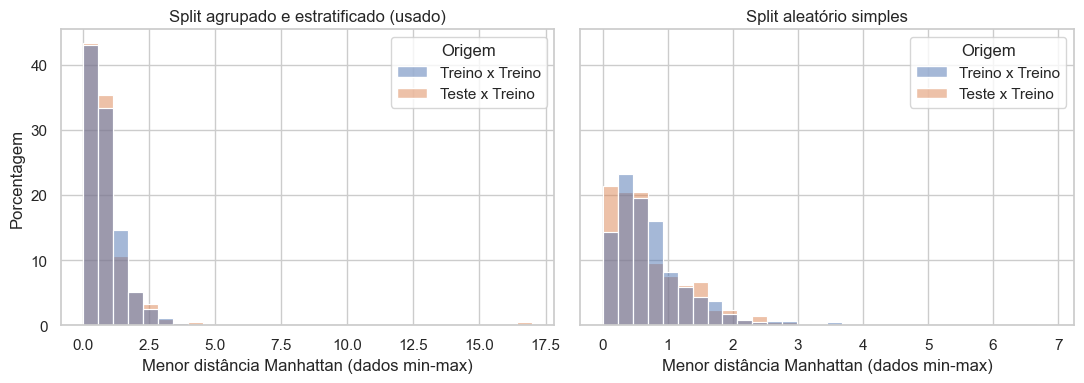

In [13]:
tt_agrupado, ts_agrupado = distancias_minimas(X_treino, X_teste) # split agrupado (o que usamos)

X_treino_aleat, X_teste_aleat = train_test_split(
    X, test_size = TAMANHO_TESTE, random_state = SEMENTE_ALEATORIA
)
tt_aleat, ts_aleat = distancias_minimas(X_treino_aleat, X_teste_aleat)

figura, eixos = plt.subplots(1, 2, figsize = (11, 4), sharey = True)
for eixo, (tt, ts), titulo in zip(
    eixos, 
    [(tt_agrupado, ts_agrupado), (tt_aleat, ts_aleat)],
    ["Split agrupado e estratificado (usado)", "Split aleatório simples"],
):
    df_dist = pd.concat(
        [
            pd.DataFrame({"valor": tt, "Origem": "Treino x Treino"}),
            pd.DataFrame({"valor": ts, "Origem": "Teste x Treino"}),
        ]
    )
    bins = np.histogram_bin_edges(df_dist["valor"], bins = 30)
    sns.histplot(
        data = df_dist, x = "valor", hue = "Origem", bins = bins, alpha = 0.5,
        stat = "percent", common_norm = False, ax = eixo,
    )
    rotula(eixo, "Menor distância Manhattan (dados min-max)", "Porcentagem", titulo)

figura.tight_layout()
salva_figura(figura, "01_checagem_split")

for nome, (tt, ts) in {
    "agrupado": (tt_agrupado, ts_agrupado),
    "aleatório": (tt_aleat, ts_aleat),
}.items():
    p_valor = mannwhitneyu(tt, ts, alternative = "less").pvalue
    print(
        f"Split {nome}: mediana treino-treino = {np.median(tt):.3f}, "
        f"mediana teste-treino = {np.median(ts):.3f}, p-valor = {p_valor:.3f}"
    )
    print(
        f"Vizinho a menos de 0,1: treino-treino = {np.mean(tt < 0.1):.1%}, "
        f"teste-treino = {np.mean(ts < 0.1):.1%}"
    )

No split agrupado, a mediana das menores distâncias é 0,661 em treino-treino e 0,605 em teste-treino, e o p-valor é 0,293. O p-valor não é pequeno, então não há evidência de que o teste esteja mais longe do treino do que o treino está de si mesmo (a mediana teste-treino é, inclusive, um pouco menor). Como a diferença entre as medianas é pequena, esse teste sozinho não permite concluir nada sobre vazamento. Por isso olhamos também a proporção de substâncias com um vizinho quase idêntico (distância menor que 0,1).

No split aleatório simples, o teste tem mais desses vizinhos no treino (14,7%) do que o próprio treino tem entre si (10,3%), que é o padrão típico de vazamento. No split agrupado isso se inverte: 9,8% no treino-treino e 1,9% no teste-treino, pois as substâncias quase redundantes ficam juntas dentro de um mesmo conjunto. 

O gráfico da esquerda tem o eixo esticado até cerca de 17 por causa de uma única substância de teste muito distante de todo o treino (as demais ficam abaixo de cerca de 4,5); isso quase não altera as medianas, mas mostra que o teste contém ao menos uma substância fora da região coberta pelo treino.

Há ainda um limite dessa análise: em 41 dimensões as distâncias tendem a se concentrar (maldição da dimensionalidade [10][15]) e o teste tem só 215 exemplos, então o teste de hipótese tem pouco poder. Por isso a garantia principal vem da construção do split, de modo que nenhum grupo de substâncias quase redundantes apareça nos dois conjuntos (0 grupos em comum). 

Já a estratificação é apenas aproximada, pois os grupos precisam ficar inteiros de um lado só, de modo que o treino tem 34,9% de RB e o teste 29,3% (no conjunto todo são 33,7%). Isso muda o baseline no teste (acurácia de 70,7%) e precisa ser lembrado ao comparar o teste com a validação cruzada. O arredondamento para o inteiro mais próximo é uma escolha conservadora, visto que ele organiza as 1055 substâncias em 999 grupos (o maior tem 6 substâncias), e um arredondamento mais fino formaria mais grupos (e menores), de modo que substâncias parecidas acabariam em grupos diferentes e o split protegeria menos contra exemplos parecidos.

### 5. Análise exploratória dos dados

#### 5.1 O que será feito

A análise exploratória usa somente o conjunto de treino, visto que olhar para o teste para escolher transformações ou atributos também é uma forma de vazamento [10]. Vamos investigar a qualidade dos dados, balanço das classes, esparsidade e distribuição dos descritores, relação deles com o target, correlação entre eles e uma projeção por PCA. As conclusões orientarão as decisões de modelagem (normalização, seleção de atributos e métrica).

#### 5.2 Estrutura e qualidade

Primeiramente, vamos analisar os tipos dos atributos e se os valores de treino possuem algum valor ausente ou linha duplicada:

In [14]:
print("Tipos dos atributos:")
print(X_treino.dtypes.value_counts().to_string())
print(f"\nValores ausentes no treino: {X_treino.isna().sum().sum()}")
print(f"Linhas duplicadas no treino: {X_treino.duplicated().sum()}")

X_treino.describe().T.round(3)

Tipos dos atributos:
int64      24
float64    17

Valores ausentes no treino: 0
Linhas duplicadas no treino: 1


,count,mean,std,min,25%,50%,75%,max
SpMax_L,840.0,4.791,0.532,3.000,4.494,4.828,5.163,6.330
J_Dz(e),840.0,3.067,0.837,0.804,2.494,3.041,3.419,9.178
nHM,840.0,0.725,1.500,0.000,0.000,0.000,1.000,12.000
F01_N-N,840.0,0.042,0.262,0.000,0.000,0.000,0.000,3.000
F04_C-N,840.0,0.942,2.026,0.000,0.000,0.000,1.000,16.000
NssssC,840.0,0.287,1.083,0.000,0.000,0.000,0.000,13.000
nCb-,840.0,1.642,2.253,0.000,0.000,1.000,3.000,18.000
C%,840.0,37.206,8.994,10.000,30.800,37.500,43.350,60.700
nCp,840.0,1.382,1.958,0.000,0.000,1.000,2.000,24.000
nO,840.0,1.788,1.789,0.000,0.000,2.000,3.000,12.000


Agora vamos analisar a esparsidade dos descritores (a fração de exemplos com valor 0 em cada um) e plotar dois gráficos, um para o balanço das classes e outro para a esparsidade:

Descritores com mais de 90% de zeros: 9
Descritores com mais de 50% de zeros: 20


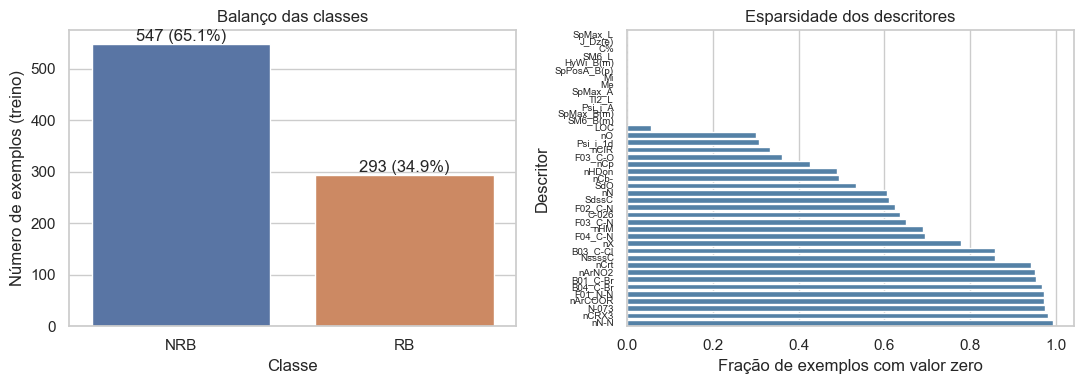

In [15]:
figura, eixos = plt.subplots(1, 2, figsize = (11, 4))

contagem = y_treino.map(NOME_CLASSE).value_counts().reindex(["NRB", "RB"])
sns.barplot(x = contagem.index, y = contagem.values, ax = eixos[0], hue = contagem.index, legend = False)
for i, valor in enumerate(contagem.values):
    eixos[0].text(i, valor, f"{valor} ({valor / contagem.sum():.1%})", ha = "center", va = "bottom")
rotula(eixos[0], "Classe", "Número de exemplos (treino)", "Balanço das classes")

fracao_zeros = (X_treino == 0).mean().sort_values()
sns.barplot(x = fracao_zeros.values, y = fracao_zeros.index, ax = eixos[1], color = "steelblue")
rotula(eixos[1], "Fração de exemplos com valor zero", "Descritor", "Esparsidade dos descritores")
eixos[1].tick_params(axis = "y", labelsize = 7)

figura.tight_layout()
salva_figura(figura, "02_balanco_e_esparsidade")

print(f"Descritores com mais de 90% de zeros: {(fracao_zeros > 0.9).sum()}")
print(f"Descritores com mais de 50% de zeros: {(fracao_zeros > 0.5).sum()}")

Isso nos permite observar:

- Qualidade: os 41 descritores são numéricos (24 inteiros, 17 contínuos), sem valores ausentes. Há 3 pares de linhas idênticas no conjunto todo (6 substâncias): um par ficou inteiro no treino e dois ficaram inteiros no teste. Como linhas idênticas pertencem ao mesmo grupo, nunca são separadas entre treino e teste;
- Balanceamento: cerca de dois terços das substâncias são NRB (65,1%) e um terço são RB (34,9%). O desbalanceamento é moderado, mas é o suficiente para que a acurácia seja uma métrica enganosa (pode parecer boa à primeira vista, mas está apenas se aproveitando do desbalanceamento);
- Esparsidade: 9 dos descritores têm mais de 90% de valores iguais a zero e 20 têm mais de 50%. São, em geral, contagem de grupos ou de átomos (por exemplo `B01_C-Br`, `nArNO2` e `F01_N-N`), que só são diferentes de zero em poucas substâncias. Esses descritores têm pouca variância e são candidatos naturais à remoção por limiar de variância.

#### 5.3 Distribuição dos descritores

Para visualizar as distribuições, vamos plotar um histograma de cada descritor (contagem de substâncias em cada faixa de valores) e, em seguida, calcular a variância dos descritores após a normalização min-max, antes de discutir os resultados.

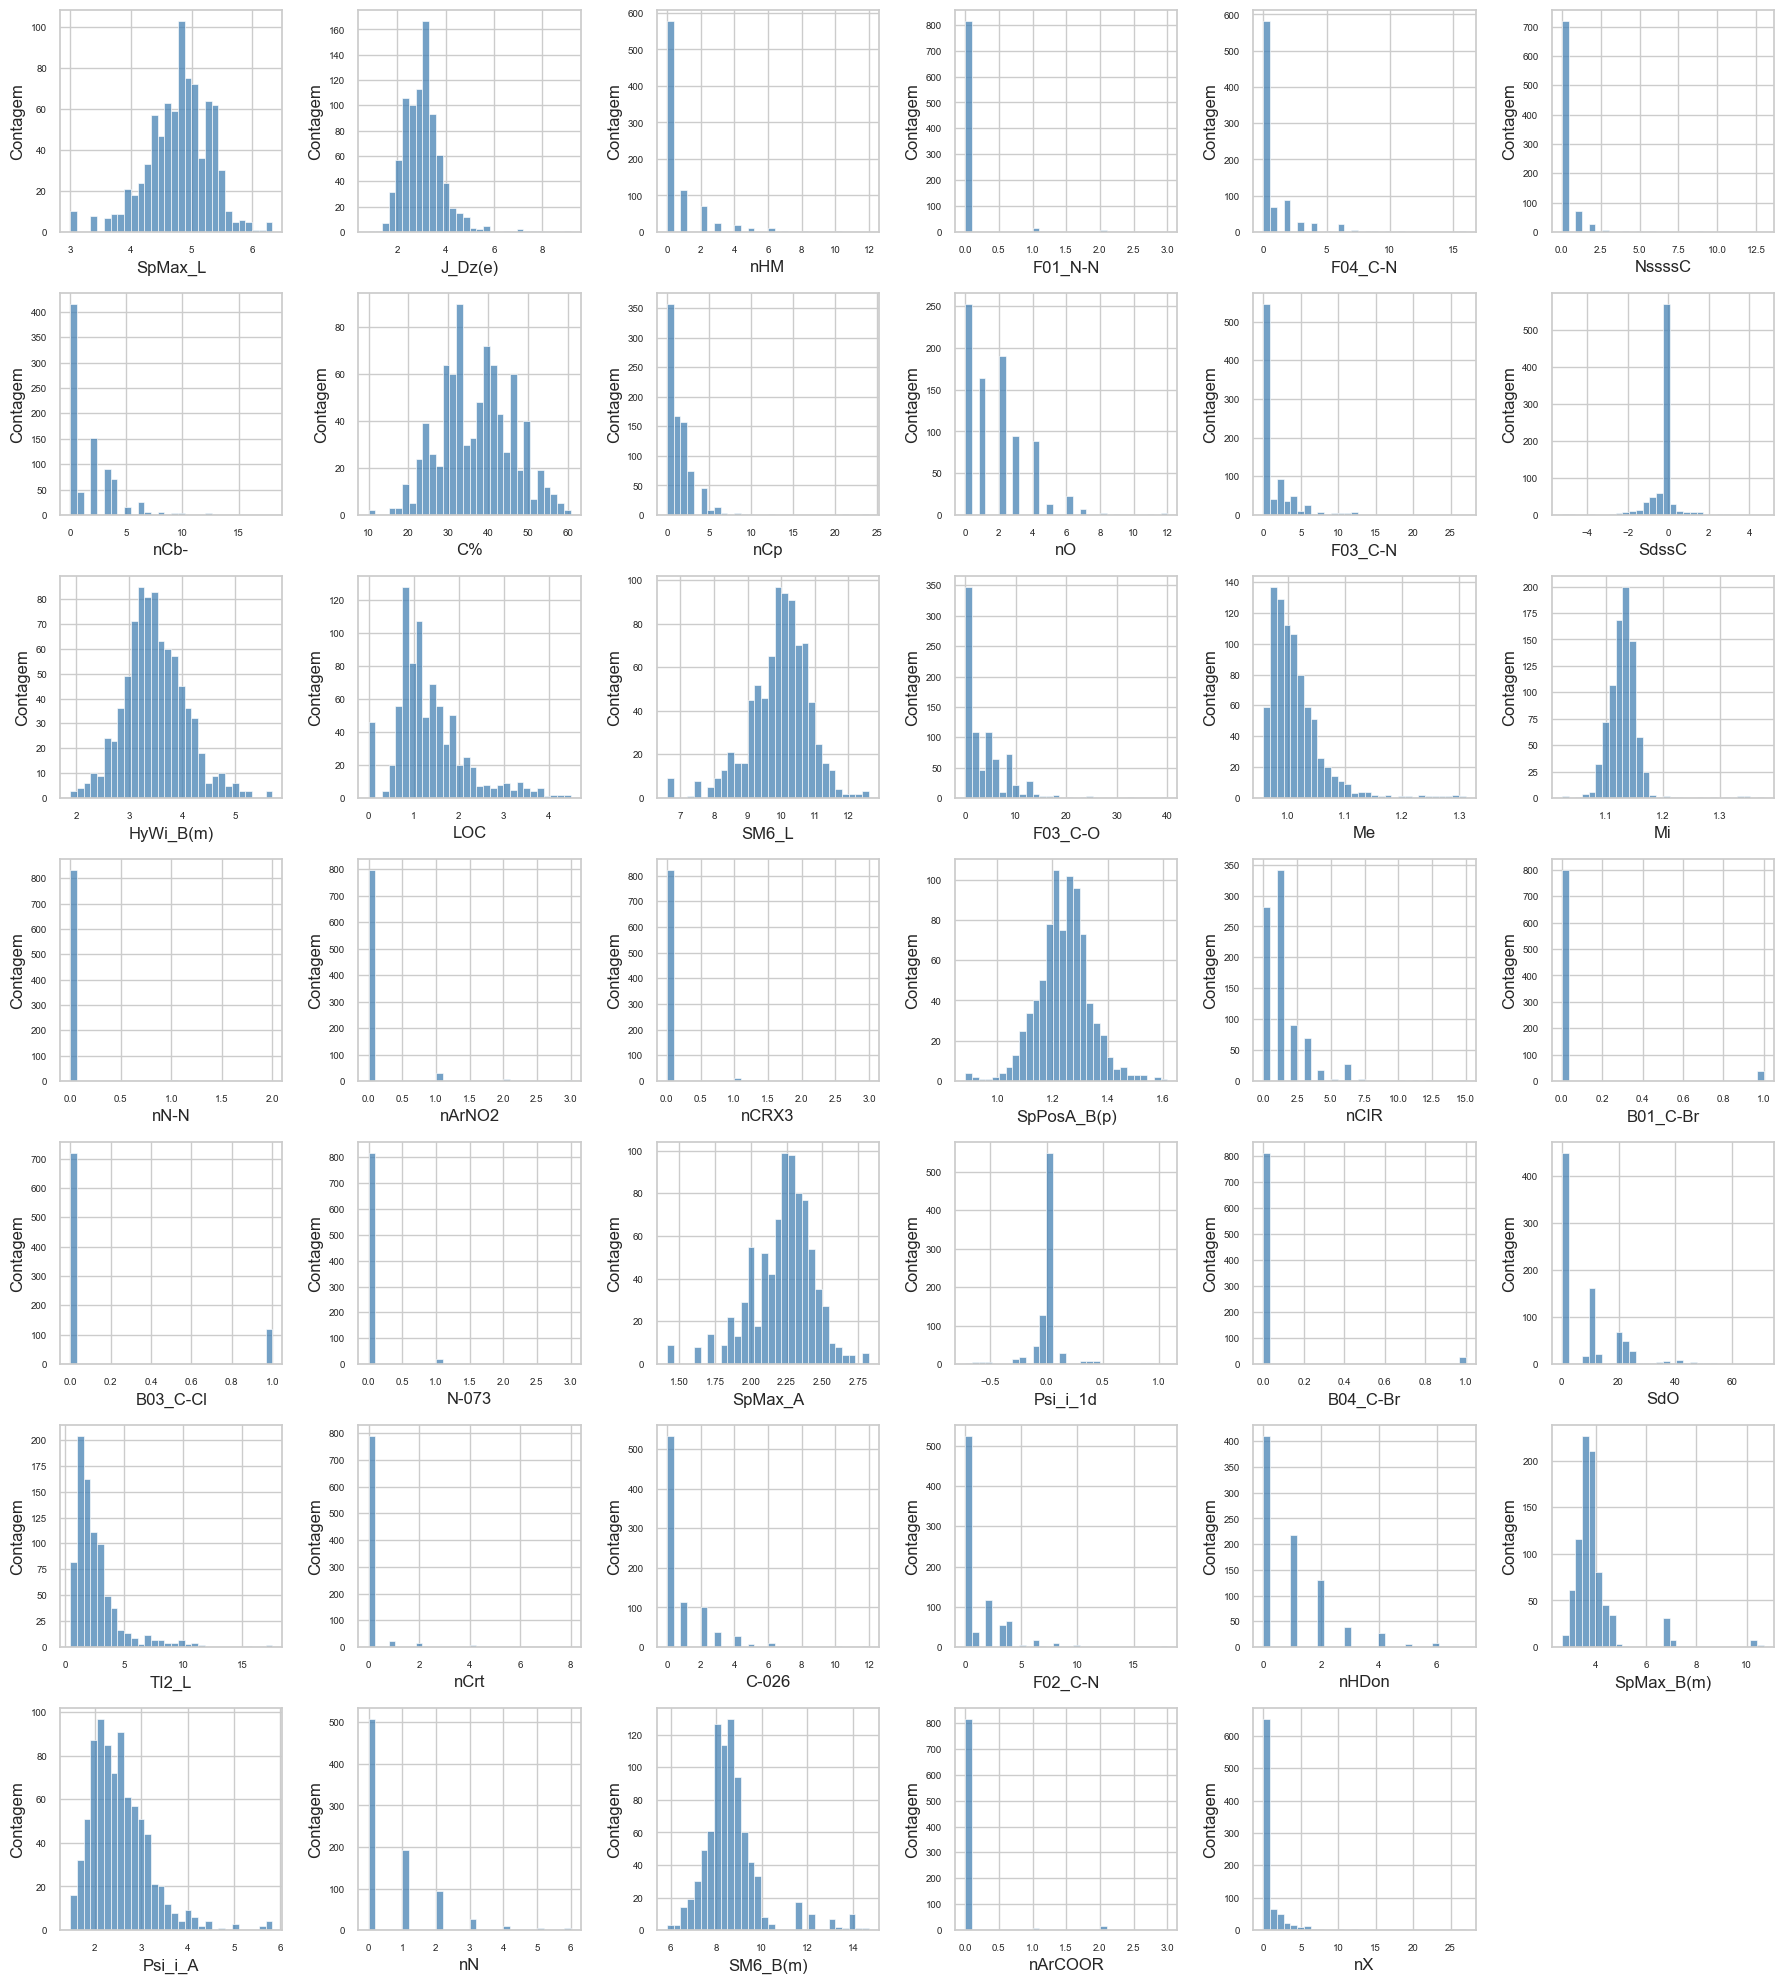

In [16]:
figura, eixos = plt.subplots(7, 6, figsize = (18, 20))
eixos = eixos.ravel()

for eixo, coluna in zip(eixos, X_treino.columns):
    sns.histplot(X_treino[coluna], bins = 30, ax = eixo, color = "steelblue")
    rotula(eixo, coluna, "Contagem")
    eixo.tick_params(labelsize = 7)

for eixo in eixos[len(X_treino.columns):]:
    eixo.axis("off")

figura.tight_layout()
salva_figura(figura, "03_distribuicoes")

In [17]:
# variância dos descritores após normalização min-max (insumo para limiar de variância)
variancia_minmax = pd.Series(
    MinMaxScaler().fit_transform(X_treino).var(axis = 0, ddof = 0), index = X_treino.columns
).sort_values()

print("Variância min-max dos descritores:")
print(variancia_minmax.describe().round(4).to_string())
print("\nMenores variâncias:")
print(variancia_minmax.head(6).round(4).to_string())

Variância min-max dos descritores:
count    41.0000
mean      0.0190
std       0.0191
min       0.0027
25%       0.0076
50%       0.0156
75%       0.0233
max       0.1224

Menores variâncias:
nN-N     0.0027
N-073    0.0039
nCRX3    0.0051
nCrt     0.0061
SdssC    0.0062
nCp      0.0066


-------------------------------------------------------------------------------------------------------------------
Podemos observar que os descritores têm formas e escalas muito diferentes: contagens com um grande pico em zero e cauda longa (como `nHM`, `nCrt`, `F04_C-N`), índices contínuos aproximadamente simétricos ou assimétricos (como `SpMax_L` e `LOC`) e porcentagens (`C%`, de 10 a 61). Isso reforça duas decisões:

1. Normalizar os dados para os algoritmos sensíveis à escala (k-NN, regressão logística e SVM), porque a escala de `C%` dominaria a de um descritor como `Psi_i_1d`;
2. Deixar que o `optuna` teste normalizações diferentes.

A variância após a normalização min-max varia de 0,0027 (`nN-N`) a 0,12, com mediana de 0,016. É por isso que o intervalo do limiar de variância no `optuna` vai de 1e-4 a 3e-2: acima de 3e-2 a maior parte dos atributos seria removida e, abaixo de cerca de 0,0027 (a menor variância observada), nenhum atributo seria removido. Ou seja, a parte inferior do intervalo equivale a "não remover nada".

#### 5.4 Relação dos descritores com o target

Vamos calcular a correlação de cada descritor com o target (0 = NRB; 1 = RB). Com um target binário, essa é a correlação ponto-bisserial ($r_{pb}$). Ela mede apenas a relação linear individual; um descritor pouco correlacionado sozinho ainda pode ser útil se combinado com outros. 

SpMax_L       -0.424
SpMax_A       -0.413
SpPosA_B(p)   -0.378
SM6_B(m)      -0.377
SM6_L         -0.368
HyWi_B(m)     -0.358
nCb-          -0.345
C-026         -0.325
nHM           -0.307
SpMax_B(m)    -0.299
nCIR          -0.288
F02_C-N       -0.272
LOC            0.271
F04_C-N       -0.255
F03_C-N       -0.254


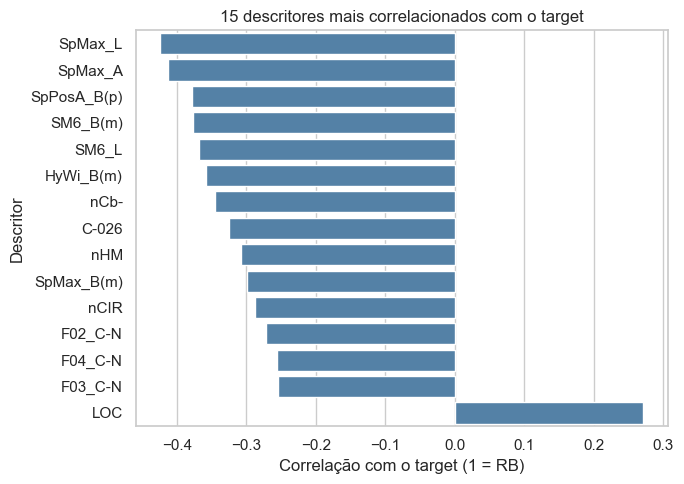

In [18]:
corr_alvo = X_treino.corrwith(y_treino).sort_values()
principais = corr_alvo.abs().sort_values(ascending = False).head(15).index
corr_principais = corr_alvo.reindex(principais).sort_values()

figura, eixo = plt.subplots(figsize = (7, 5))
sns.barplot(x = corr_principais.values, y = corr_principais.index, ax = eixo, color = "steelblue")
rotula(eixo, "Correlação com o target (1 = RB)", "Descritor", "15 descritores mais correlacionados com o target")
figura.tight_layout()
salva_figura(figura, "04_correlacao_com_alvo")

print(corr_alvo.reindex(principais).round(3).to_string())

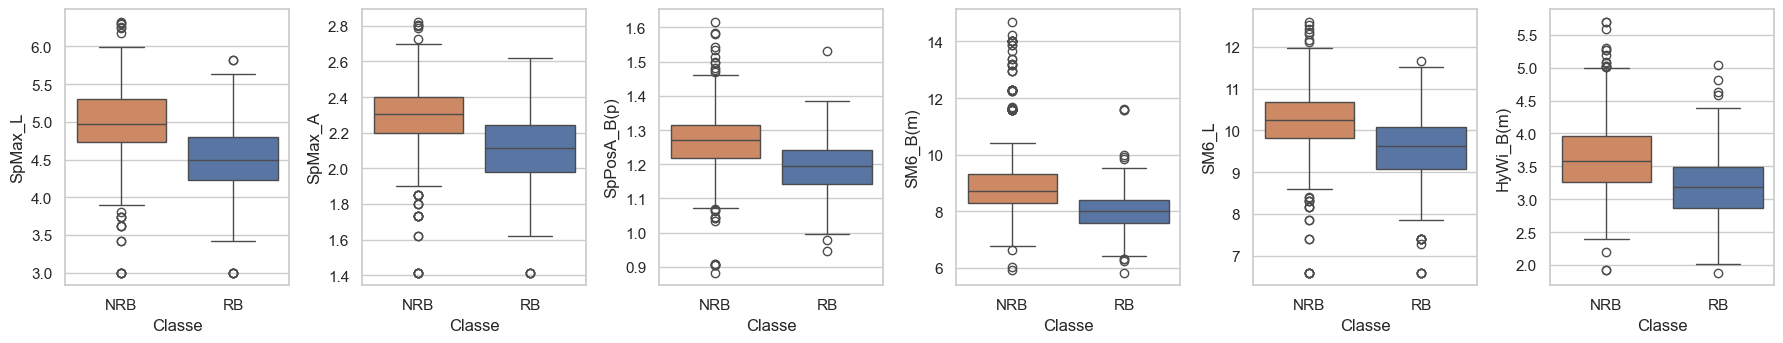

In [19]:
seis_principais = list(principais[:6])

figura, eixos = plt.subplots(1, 6, figsize = (18, 3.6))
for eixo, coluna in zip(eixos, seis_principais):
    sns.boxplot(
        x = y_treino.map(NOME_CLASSE), y = X_treino[coluna], order = ["NRB", "RB"],
        hue = y_treino.map(NOME_CLASSE), legend = False, ax = eixo,
    )
    rotula(eixo, "Classe", coluna)

figura.tight_layout()
salva_figura(figura, "05_boxplots_principais")

Podemos observar que nenhum descritor sozinho separa bem as classes: a maior correlação em módulo com o target é 0,42 (`SpMax_L`, negativa). Os sinais são coerentes entre si. Descritores que crescem com o tamanho e a complexidade da molécula (`SpMax_L`, `SpMax_A`, `SpPosA_B(p)`, `SM6_L`, `HyWi_B(m)`), além do número de carbonos de benzenos substituídos (`nCb-`), do fragmento `C-026` e do número de átomos pesados (`nHM`), estão associados a NRB (correlação negativa, entre -0,31 e -0,42), enquanto `LOC` é o único dos 15 principais com correlação positiva com RB (0,27). 

Os boxplots mostram distribuições que se sobrepõem bastante entre as classes, então a previsão dependerá das combinações de muitos descritores. Essa é uma associação estatística, e não uma relação causal. 

#### 5.5 Correlação entre os descritores

Descritores muito correlacionados carregam informação redundante. Isso importa para o Naive Bayes (supõe independência condicional entre atributos), para a regressão logística (coeficientes instáveis) e para a decisão de usar PCA ou seleção de atributos.

Vamos agora analisar a correlação dos descritores:

Pares com |correlação| > 0.9: 4
Pares com |correlação| > 0.7: 19


,descritor_1,descritor_2,correlacao
738,SM6_B(m),SpMax_B(m),0.922
339,SpMax_A,SM6_L,0.918
325,SpMax_A,SpMax_L,0.914
91,SM6_L,SpMax_L,0.907
676,nN,F03_C-N,0.860
646,Psi_i_A,Me,0.853
114,F03_C-O,nO,0.841
401,B04_C-Br,B01_C-Br,0.826
715,SM6_B(m),HyWi_B(m),0.816
49,F03_C-N,F04_C-N,0.815


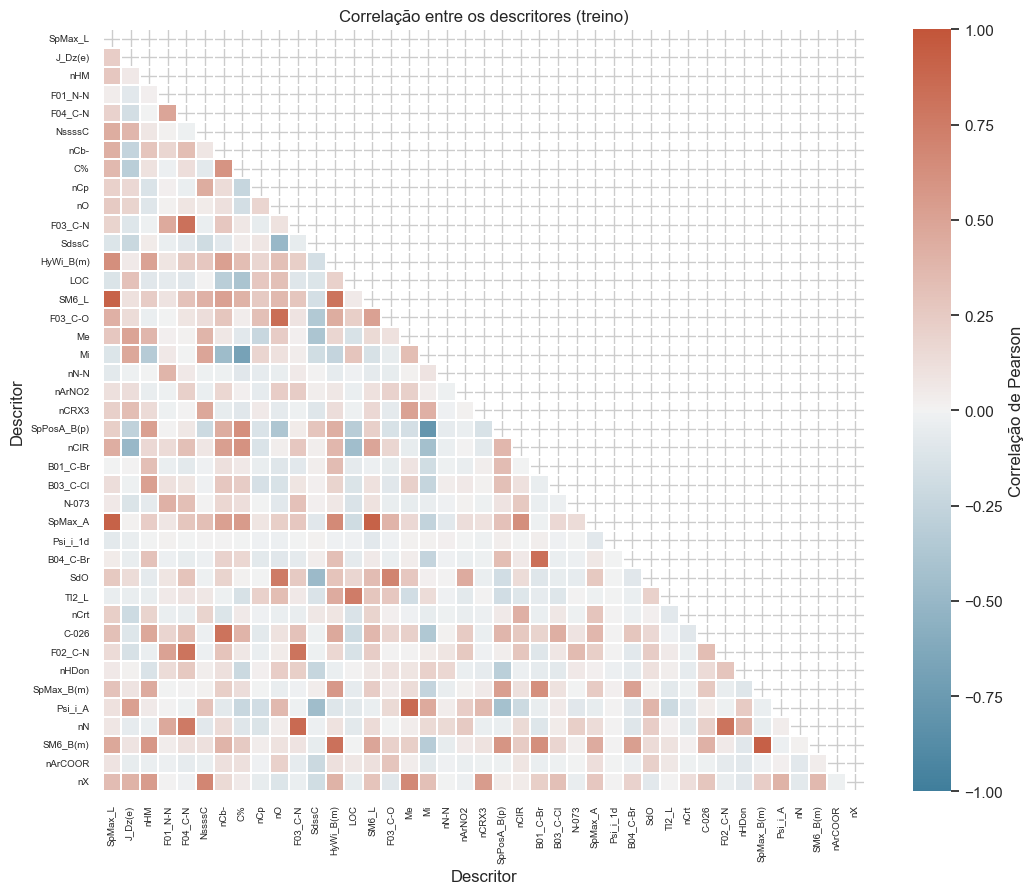

In [20]:
corr = X_treino.corr()
mascara = np.triu(np.ones_like(corr, dtype = bool))

figura, eixo = plt.subplots(figsize = (11, 9))
sns.heatmap(
    corr, mask = mascara, cmap = sns.diverging_palette(230, 20, as_cmap = True),
    center = 0, vmin = -1, vmax = 1, square = True, linewidths = 0.2,
    cbar_kws = {"label": "Correlação de Pearson"}, ax = eixo,
)
rotula(eixo, "Descritor", "Descritor", "Correlação entre os descritores (treino)")
eixo.tick_params(labelsize = 7)
figura.tight_layout()
salva_figura(figura, "06_correlacao_entre_descritores")

pares = corr.where(~mascara).stack().dropna().rename("correlacao").reset_index()
pares.columns = ["descritor_1", "descritor_2", "correlacao"]
pares["abs"] = pares["correlacao"].abs()
pares = pares.sort_values("abs", ascending = False)

print(f"Pares com |correlação| > 0.9: {(pares['abs'] > 0.9).sum()}")
print(f"Pares com |correlação| > 0.7: {(pares['abs'] > 0.7).sum()}")
pares.drop(columns = "abs").head(10).round(3)

Podemos observar que a maior parte dos pares de descritores tem correlação baixa, mas há blocos de redundância: 4 pares têm |correlação| acima de 0,9 e 19 pares acima de 0,7. Os mais correlacionados são índices espectrais da mesma família (`SpMax_A`, `SpMax_L`, `SM6_L` / `SM6_B(m)` e `SpMax_B(m)`), que descrevem aspectos parecidos da topologia da molécula e contagens relacionadas (`nN` e `F03_C-N`, 0,86 / `F03_C-O` e `nO`, 0,84 / `F03_C-N` e `F04_C-N`, 0,82). 

Como consequências esperadas, podemos citar que o Naive Bayes julgará todos os atributos como independentes e a regressão logística pode ter coeficientes instáveis; a seleção de atributos e o PCA são alternativas naturais, e o `optuna` poderá testá-las. 

#### 5.6 Projeção por PCA

Para ter uma ideia da estrutura global dos dados, projetamos o treino em duas componentes principais (dados padronizados, o PCA foi ajustado só no treino) e vemos quanta variância cada componente explica. Isso também mostra quantas componentes seriam necessárias para preservar a maior parte da informação.

Componentes para explicar 80% da variância: 12 de 41
Componentes para explicar 90% da variância: 17 de 41
Componentes para explicar 95% da variância: 22 de 41


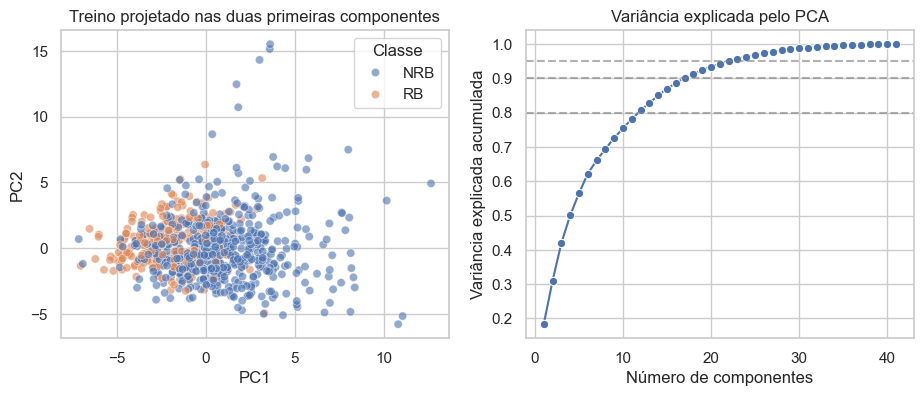

In [21]:
X_padronizado = StandardScaler().fit_transform(X_treino)
pca_exploratorio = PCA(random_state = SEMENTE_ALEATORIA).fit(X_padronizado)
componentes = pca_exploratorio.transform(X_padronizado)
variancia_acumulada = np.cumsum(pca_exploratorio.explained_variance_ratio_)

figura, eixos = plt.subplots(1, 2, figsize = (11, 4))

sns.scatterplot(
    x = componentes[:, 0], y = componentes[:, 1], hue = y_treino.map(NOME_CLASSE).values,
    hue_order = ["NRB", "RB"], alpha = 0.6, ax = eixos[0],
)
eixos[0].legend(title = "Classe")
rotula(eixos[0], "PC1", "PC2", "Treino projetado nas duas primeiras componentes")

sns.lineplot(
    x = np.arange(1, len(variancia_acumulada) + 1), y = variancia_acumulada,
    marker = "o", ax = eixos[1]
)
for limiar in (0.8, 0.9, 0.95):
    eixos[1].axhline(limiar, linestyle = "--", color = "gray", alpha = 0.6)
rotula(eixos[1], "Número de componentes", "Variância explicada acumulada", "Variância explicada pelo PCA")

figura.tight_layout()
salva_figura(figura, "07_pca_exploratorio")

for limiar in (0.8, 0.9, 0.95):
    n_comp = int(np.searchsorted(variancia_acumulada, limiar) + 1)
    print(f"Componentes para explicar {limiar:.0%} da variância: {n_comp} de {X_treino.shape[1]}")

Podemos observar que no plano das duas primeiras componentes (que explicam cerca de 31% da variância) as classes se sobrepõem bastante, mas as substâncias RB se concentram na região de PC1 baixo, ou seja, há uma tendência global que um modelo pode aproveitar, sem separação limpa em 2D. 

A variância está espalhada, de modo que são necessárias 12 componentes para 80%, 17 para 90% e 22 para 95% (de 41). Ou seja, o PCA reduziria o espaço a cerca de 40% do tamanho original (17 de 41 componentes) mantendo 90% da variância, mas nenhuma componente isolada concentra a informação.

#### 5.7 Decisões de modelagem tiradas da exploração

Aqui apresento um breve resumo do que foi constatado nas seções acima, onde analisamos quais seriam as melhores escolhas para modelagem:

1. Métrica: target desbalanceado (1:2) --> usar o Coeficiente de Correlação de Matthews (MCC), e não a acurácia
2. Validação: substâncias quase redundantes existem --> CV (validação cruzada) estratificada e agrupada
3. Normalização: escalas muito diferentes --> obrigatória para k-NN, regressão logística e SVM; árvores e Naive Bayes não precisam
4. Esparsidade e redundância: descritores quase constantes e blocos correlacionados --> deixar o `optuna` testar limiar de variância, RFE e PCA (e também "nenhuma redução")
5. Nenhum descritor domina: esperamos modelos multivariados com desempenho moderado, e não separações quase perfeitas como as dos datasets didáticos 

### 6. Métrica de desempenho e modelo baseline

#### 6.1 Por que o MCC

Nosso target é binário e desbalanceado (cerca de 1 RB para cada 2 NRB). Nessa situação a acurácia engana: um modelo que sempre diz "NRB" já acerta cerca de 65%. Usaremos o Coeficiente de Correlação de Matthews (MCC) [2][3] como métrica principal:

$$
\mathrm{MCC} = \frac{VP \cdot VN - FP \cdot FN}{\sqrt{(VP+FP)(VP+FN)(VN+FP)(VN+FN)}}
$$

O MCC usa as quatro células da matriz de confusão, vai de -1 (discordância total) a +1 (previsão perfeita) e vale 0 para um modelo que não aprendeu nada (como o baseline). Chicco e Jurman [2] mostram que ele é mais informativo que a acurácia e o F1 em dados desbalanceados, porque só é alto se o modelo vai bem nas duas classes. Como métricas complementares reportaremos a acurácia balanceada, F1, precisão e revocação da classe RB, AUC-ROC e AUC-PR.

#### 6.2 Baseline

O baseline é o `DummyClassifier`, que sempre prevê a classe mais frequente do treino. Qualquer modelo que analisarmos deve superá-lo. Avaliamos o baseline com a mesma validação cruzada usada no restante do trabalho (estratificada e agrupada, 5 partições, usando apenas o treino).

In [22]:
particoes_cv = list(
    StratifiedGroupKFold(
        n_splits = NUM_FOLDS, shuffle = True, random_state = SEMENTE_ALEATORIA
    ).split(X_treino, y_treino, groups = grupos_treino)
)

modelo_baseline = DummyClassifier(strategy = "most_frequent")

mcc_baseline = cross_val_score(
    modelo_baseline, X_treino, y_treino, cv = particoes_cv, scoring = "matthews_corrcoef"
)
acc_baseline = cross_val_score(
    modelo_baseline, X_treino, y_treino, cv = particoes_cv, scoring = "accuracy"
)

print(f"Baseline | Classe mais frequente: {NOME_CLASSE[int(y_treino.mode()[0])]} | MCC médio (CV): {mcc_baseline.mean():.3f} | acurácia média (CV): {acc_baseline.mean():.3f}")

Baseline | Classe mais frequente: NRB | MCC médio (CV): 0.000 | acurácia média (CV): 0.651


Podemos observar que o baseline MCC = 0,000 e acurácia = 0,651, como esperado: ele sempre responde NRB, acertando toda a classe majoritária e errando toda a minoritária. Isso confirma por que a acurácia sozinha seria enganosa e define o piso que os demais modelos precisam superar: MCC > 0.

### 7. Estratégia experimental

#### 7.1 Visão geral

O experimento seguirá a seguinte estrutura, e vale lembrar que em nenhum momento o conjunto de teste participa das escolhas:

1. Otimização (treino): para cada um dos 5 algoritmos, o `optuna` testa 100 conjuntos de hiperparâmetros. A função objetivo é o MCC médio em validação cruzada 5-fold (estratificada e agrupada) sobre o treino
2. Comparação (treino): os melhores pipelines de cada algoritmo são reavaliados com validação cruzada repetida em partições novas (5 repetições x 5 folds). Escolhemos o que apresentar o melhor resultado
3. Avaliação final (teste): os pipelines ajustados no treino completo são avaliados no teste, uma única vez
4. Explicação: *permutation importance* e SHAP no modelo campeão

#### 7.2 Pipelines e prevenção de vazamento

Cada candidato é um `Pipeline` do `scikit-learn`:

$$ \text{normalização} \longrightarrow \text{redução de dimensionalidade} / \text{seleção de atributos} \longrightarrow \text{algoritmo}$$

Como tudo está dentro do pipeline, normalizadores, PCA e seletores são ajustados apenas nos dados de treino de cada fold, o que evita o vazamento por pré-processamento [10][12].

Vamos tratar mais a fundo a normalização. Algoritmos baseados em distância ou em margem (k-NN, regressão logística e SVM) exigem atributos na mesma escala, então eles sempre normalizam, e o `optuna` escolhe entre normalização padrão (`StandardScaler`) e min-max (`MinMaxScaler`). Árvores (floresta aleatória) e Naive Bayes Gaussiano não dependem da escala dos atributos e, por isso, só normalizam quando a estratégia de redução escolhida exige isso.

Agora, ao tratar da redução de dimensionalidade e seleção de atributos controladas pelo `optuna`, o conjunto tem 41 atributos (mais que os 20 exigidos para essa estratégia), então o hiperparâmetro `reducao` permite ao `optuna` escolher uma entre quatro opções, cada uma com seus próprios hiperparâmetros:

| `reducao` | O que faz | Hiperparâmetro otimizado |
|---|---|---|
| nenhuma | usa os 41 descritores | nenhum |
| `variancia` | normaliza min-max e remove descritores com variância abaixo de um limiar (descritores quase constantes) [10] | `limiar_variancia` |
| `pca` | projeta nas componentes principais que explicam uma fração da variância (dados padronizados) [10] | `pca_variancia_explicada` |
| `rfe` | remoção recursiva de atributos guiada pelos coeficientes de uma regressão logística [14] | `rfe_num_atributos` , `rfe_passo` |

#### 7.3 Validação cruzada 

Usamos `StratifiedGroupKFold` com 5 partições, de modo que cada fold mantém a proporção RB/NRB e substâncias do mesmo grupo (quase redundantes) nunca ficam em folds diferentes. Todos os algoritmos usam exatamente as mesmas partições durante a otimização, o que torna a comparação justa.

#### 7.4 Otimização com o `optuna`

O `optuna` usa por padrão o otimizador TPE (Tree-structured Parzen Estimator), que navega o espaço de busca de forma bayesiana e é adequado para estudos de 100 a 1000 tentativas [4][5][10]. Usamos `multivariate = True` (leva em conta dependência de hiperparâmetros) com `group = True` (necessário porque o espaço é condicional, de modo que o hiperparâmetro `gamma` do SVM só existe em tipos específicos de kernel, por exemplo). Hiperparâmetros que variam por ordens de grandeza são sorteados em escala logarítmica, para evitar o viés de amostragem.

Em cada estudo, a primeira tentativa é uma configuração próxima do padrão do `scikit-learn` (sem redução), que serve de ponto de comparação, de modo que ela mostra quanto a otimização "ganhou" sobre "usar o algoritmo como ele vem".

#### 7.5 Espaço de busca e justificativa

Os intervalos abaixo foram escolhidos a partir da documentação do `scikit-learn`, dos valores padrão de cada algoritmo (que ficam dentro dos intervalos) e do tamanho do problema (840 exemplos de treino, 41 atributos).

**k-NN** [16]

| **Hiperparâmetro** | **Intervalo** | **Justificativa** |
| --- | --- | --- |
| `num_vizinhos` | 1 a 51 (só ímpares) | ímpar evita empates em classificação binária; 51 é cerca de 6% do treino, e um k muito grande aproxima o modelo do baseline |
| `pesos` | `uniform` , `distance` | testa se vizinhos mais próximos devem pesar mais |
| `potencia_minkowski` | 1 a 2 | p = 1 é a distância Manhattan e p = 2 a Euclidiana; em alta dimensão a Manhattan costuma ser mais robusta [10][15] | 
| `normalizacao` | `padrao` , `minmax` | distâncias dependem da escala; normalizar é obrigatório |


**Regressão logística** [15]

| **Hiperparâmetro** | **Intervalo** | **Justificativa** |
| --- | --- | --- |
| `C` | 1e-3 a 1e2 (log)| inverso da força da regularização L2; varia por ordens de grandeza |
| `peso_classes` | nenhum, `balanced` | compensa o desbalanceamento 1:2 |
| `normalizacao` | `padrao` , `minmax` | convergência e regularização dependem da escala |


**SVM** [11]

| **Hiperparâmetro** | **Intervalo** | **Justificativa** |
| --- | --- | --- |
| `kernel` | `rbf` , `linear` , `poly` | fronteira não linear, linear ou polinomial |
| `C` | 1e-2 a 1e2 (log) | penalidade por erro de classificação (margem rígida vs. flexível); limite superior evita linear/poly lentos demais |
| `gamma` (rbf, poly) | 1e-4 a 1 (log) | alcance de cada exemplo; o padrão `scale` (cerca de 0,024 com dados padronizados) está dentro do intervalo |
| `grau` (poly) | 2 a 4 | graus altos geram overfit com 840 exemplos | 
| `peso_classes` | nenhum , `balanced` | desbalanceamento |
| `normalizacao` | `padrao` , `minmax` | o SVM é sensível à escala | 


**Naive Bayes Gaussiano**

| **Hiperparâmetro** | **Intervalo** | **Justificativa** |
| --- | --- | --- |
| `var_smoothing` | 1e-12 a 1e-1 (log) | fração da maior suavização somada às variâncias de cada classe; o padrão (1e-9) está no intervalo e valores altos suavizam o modelo |

O Naive Bayes tem poucos hiperparâmetros, então a otimização aqui depende muito da escolha da redução (o PCA, por exemplo, decorrelaciona os atributos e aproxima a hipótese de independência).


**Floresta aleatória** [9]

| **Hiperparâmetro** | **Intervalo** | **Justificativa** |
| --- | --- | --- |
| `num_arvores` | 50 a 500 (log) | mais árvores reduzem a variância, com retorno decrescente |
| `criterio` | `gini` , `entropy` | duas medidas de impureza vistas em aula | 
| `profundidade_max` | 3 a 40 | controla o overfitting; 40 é praticamente "sem limite" para 840 exemplos |
| `min_exemplos_split` | 2 a 20 | número mínimo de exemplos para dividir um vértice |
| `min_exemplos_folha` | 1 a 10 | número mínimo de exemplos em uma folha | 
| `fracao_atributos` | 0,05 a 1 | fração de atributos sorteada em cada divisão (o padrão √41/41 ≈ 0,16 está dentro; 1 equivale a bagging) |
| `peso_classes` | nenhum , `balanced` , `balanced_subsample` | desbalanceamento |


**Hiperparâmetros que não serão otimizados:** não vamos otimizar o número de iterações máximas de solvers (fixadas para garantir convergência), a semente aleatória e opções de paralelismo.

#### 7.6 Código: criação dos pipelines

A função `cria_preprocessamento` implementa a normalização e a escolha da estratégia de redução; cada função `cria_*` monta um pipeline completo de um algoritmo recebendo um objeto `trial` do `optuna` [10].

In [23]:
def cria_preprocessamento(trial, precisa_normalizar):
    """Cria as etapas de normalização e de redução/seleção de atributos
    
    trial: objeto tipo Trial do optuna
    precisa_normalizar: True se o algoritmo exige atributos na mesma escala
    
    Return:
        Lista de etapas do pipeline (pode ser vazia)"""

    reducao = trial.suggest_categorical("reducao", ["nenhuma", "variancia", "pca", "rfe"])

    etapas = []

    if reducao == "variancia":
        #a variancia depende da escala, então normalizamos min-max antes 
        limiar = trial.suggest_float("limiar_variancia", 1e-4, 3e-2, log = True)
        etapas += [MinMaxScaler(), VarianceThreshold(threshold = limiar)]

    if precisa_normalizar:
        normalizacao = trial.suggest_categorical("normalizacao", ["padrao", "minmax"])
        etapas.append(StandardScaler() if normalizacao == "padrao" else MinMaxScaler())
    elif reducao in ("pca", "rfe"):
        etapas.append(StandardScaler()) # PCA e RFE (regressão logística) exigem escala

    if reducao == "pca":
        fracao = trial.suggest_float("pca_variancia_explicada", 0.70, 0.99)
        etapas.append(PCA(n_components = fracao, random_state = SEMENTE_ALEATORIA))

    elif reducao == "rfe":
        etapas.append(
            RFE(
                LogisticRegression(max_iter = 2000),
                n_features_to_select = trial.suggest_int("rfe_num_atributos", 5, 40),
                step = trial.suggest_int("rfe_passo", 1, 5),
            )
        )

    return etapas

In [24]:
def cria_knn(trial):
    parametros = {
        "n_neighbors": trial.suggest_int("num_vizinhos", 1, 51, step = 2),
        "weights": trial.suggest_categorical("pesos", ["uniform", "distance"]),
        "p": trial.suggest_float("potencia_minkowski", 1, 2),
    }
    return make_pipeline(*cria_preprocessamento(trial, True), KNeighborsClassifier(**parametros))

In [25]:
def cria_regressao_logistica(trial):
    parametros = {
        "C": trial.suggest_float("C", 1e-3, 1e2, log = True),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        "max_iter": 5000,
    }
    return make_pipeline(*cria_preprocessamento(trial, True), LogisticRegression(**parametros))

In [26]:
def cria_svm(trial):
    kernel = trial.suggest_categorical("kernel", ["rbf", "linear", "poly"])
    parametros = {
        "kernel": kernel, 
        "C": trial.suggest_float("C", 1e-2, 1e2, log = True),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced"]),
        "max_iter": 200000,
    }

    if kernel in ("rbf", "poly"):
        parametros["gamma"] = trial.suggest_float("gamma", 1e-4, 1.0, log = True)

    if kernel == "poly":
        parametros["degree"] = trial.suggest_int("grau", 2, 4)

    return make_pipeline(*cria_preprocessamento(trial, True), SVC(**parametros))

In [27]:
def cria_naive_bayes(trial):
    parametros = {"var_smoothing": trial.suggest_float("var_smoothing", 1e-12, 1e-1, log = True)}
    return make_pipeline(*cria_preprocessamento(trial, False), GaussianNB(**parametros))

In [28]:
def cria_floresta_aleatoria(trial):
    parametros = {
        "n_estimators": trial.suggest_int("num_arvores", 50, 500, log = True),
        "criterion": trial.suggest_categorical("criterio", ["gini", "entropy"]),
        "max_depth": trial.suggest_int("profundidade_max", 3, 40),
        "min_samples_split": trial.suggest_int("min_exemplos_split", 2, 20),
        "min_samples_leaf": trial.suggest_int("min_exemplos_folha", 1, 10),
        "max_features": trial.suggest_float("fracao_atributos", 0.05, 1.0),
        "class_weight": trial.suggest_categorical("peso_classes", [None, "balanced", "balanced_subsample"]),
        "random_state": SEMENTE_ALEATORIA,
        "n_jobs" : -1,
    }

    return make_pipeline(*cria_preprocessamento(trial, False), RandomForestClassifier(**parametros))

In [29]:
ALGORITMOS = {
    "k-NN": cria_knn,
    "Regressão logística": cria_regressao_logistica,
    "SVM": cria_svm,
    "Naive Bayes": cria_naive_bayes,
    "Floresta aleatória": cria_floresta_aleatoria
}

In [30]:
# primeira configuração de cada estudo: configuração próxima do padrão do scikit-learn
CONFIGURACAO_PADRAO = {
    "k-NN": {
        "reducao": "nenhuma", 
        "normalizacao": "padrao",
        "num_vizinhos": 5,
        "pesos": "uniform",
        "potencia_minkowski": 2.0,
    },
    "Regressão logística": {
        "reducao": "nenhuma",
        "normalizacao": "padrao",
        "C": 1.0,
        "peso_classes": None,
    },
    "SVM": {
        "reducao": "nenhuma",
        "normalizacao": "padrao",
        "kernel": "rbf",
        "C": 1.0,
        "peso_classes": None,
        "gamma": 0.024,
    },
    "Naive Bayes": {
        "reducao": "nenhuma",
        "var_smoothing": 1e-9,
    },
    "Floresta aleatória": {
        "reducao": "nenhuma",
        "num_arvores": 100,
        "criterio": "gini",
        "profundidade_max": 40,
        "min_exemplos_split": 2,
        "min_exemplos_folha": 1,
        "fracao_atributos": 0.16,
        "peso_classes": None,
    },
}

#### 7.7 Código: função objetivo

A função objetivo devolve o MCC médio nos 5 folds do treino. Os folds são sempre os mesmos (`particoes_cv`). Se algum conjunto de hiperparâmetros gerar um pipeline inválido (por exemplo, um limiar de variância que remove todos os atributos), a tentativa é descartada, mas os intervalos foram escolhidos para que isso não aconteça.

In [31]:
def funcao_objetivo(trial, cria_modelo, X, y, particoes):
    """Função objetivo do optuna: MCC médio em validação cruzada"""

    modelo = cria_modelo(trial)

    try:
        metricas = cross_val_score(
            modelo, X, y, cv = particoes, scoring = "matthews_corrcoef", error_score = "raise"
        )
    except ValueError:
        raise optuna.TrialPruned()

    return metricas.mean()

### 8. Otimização de hiperparâmetros

#### 8.1 O que será feito

Para cada algoritmo criamos um estudo do `optuna` salvo em um banco SQLite (pasta `estudos_optuna/`) e rodamos até completar 100 tentativas (a primeira é a configuração padrão). Se o estudo já existir com 100 tentativas, o notebook apenas carrega.

In [32]:
ARMAZENAMENTO = f"sqlite:///{DIR_ESTUDOS / 'tiamat.db'}"

def nome_do_estudo(algoritmo):
    return "tiamat_" + algoritmo.lower().replace(" ", "_").replace("-", "")


estudos = {}

for algoritmo, cria_modelo in ALGORITMOS.items():
    estudo = optuna.create_study(
        direction = "maximize",
        study_name = nome_do_estudo(algoritmo),
        storage = ARMAZENAMENTO,
        load_if_exists = True,
        sampler = TPESampler(seed = SEMENTE_ALEATORIA, multivariate = True, group = True),
    )

    if len(estudo.trials) == 0:
        estudo.enqueue_trial(CONFIGURACAO_PADRAO[algoritmo])

    # só contam tentativas terminadas --> a enfileirada (WAITING) será executada dentro do optimize
    ja_executadas = sum(t.state.is_finished() for t in estudo.trials)
    restantes = NUM_TENTATIVAS - ja_executadas
    if restantes > 0: 
        funcao_parcial = partial(
            funcao_objetivo,
            cria_modelo = cria_modelo, X = X_treino, y = y_treino, particoes = particoes_cv,
        )
        estudo.optimize(funcao_parcial, n_trials = restantes)

    estudos[algoritmo] = estudo
    print(
        f"{algoritmo:20s} | tentativas: {len(estudo.trials)} | "
        f"melhor MCC (cv): {estudo.best_value:.3f}"
    )

k-NN                 | tentativas: 100 | melhor MCC (cv): 0.715
Regressão logística  | tentativas: 100 | melhor MCC (cv): 0.702
SVM                  | tentativas: 100 | melhor MCC (cv): 0.738
Naive Bayes          | tentativas: 100 | melhor MCC (cv): 0.575
Floresta aleatória   | tentativas: 100 | melhor MCC (cv): 0.725


In [33]:
# conferindo: quantas tentativas completas cada estudo tem?
resumo_estudos = pd.DataFrame(
    {
        algoritmo: {
            "tentativas": len(estudo.trials),
            "completas": sum(t.state.name == "COMPLETE" for t in estudo.trials),
            "podadas": sum(t.state.name == "PRUNED" for t in estudo.trials),
        }
        for algoritmo, estudo in estudos.items()
    }
).T
resumo_estudos

,tentativas,completas,podadas
k-NN,100,100,0
Regressão logística,100,100,0
SVM,100,100,0
Naive Bayes,100,100,0
Floresta aleatória,100,100,0


Todos os algoritmos superaram com folga o baseline (MCC = 0), então os descritores carregam informação útil sobre a biodegradabilidade. O SVM (0,738) e a floresta aleatória (0,725) ficaram no topo, bem próximos entre si, seguidos por k-NN (0,715) e regressão logística (0,702). O Naive Bayes foi o pior (0,575), o que é coerente com a forte correlação entre os descritores, que viola a hipótese de independência condicional do modelo.

Esses valores são o máximo entre 100 tentativas e, por isso, tendem a ser um pouco otimistas. Além disso, diferenças de poucos centésimos entre os melhores algoritmos estão dentro da variação esperada entre partições. Por isso não escolhemos o vencedor aqui: o ranking definitivo virá da validação cruzada repetida, e a estimativa de desempenho final virá do teste.

#### 8.2 Histórico da otimização

Cada ponto é uma tentativa (um conjunto de hiperparâmetros); a linha vermelha é o melhor MCC encontrado até aquele momento. A tentativa 0 é a configuração padrão.

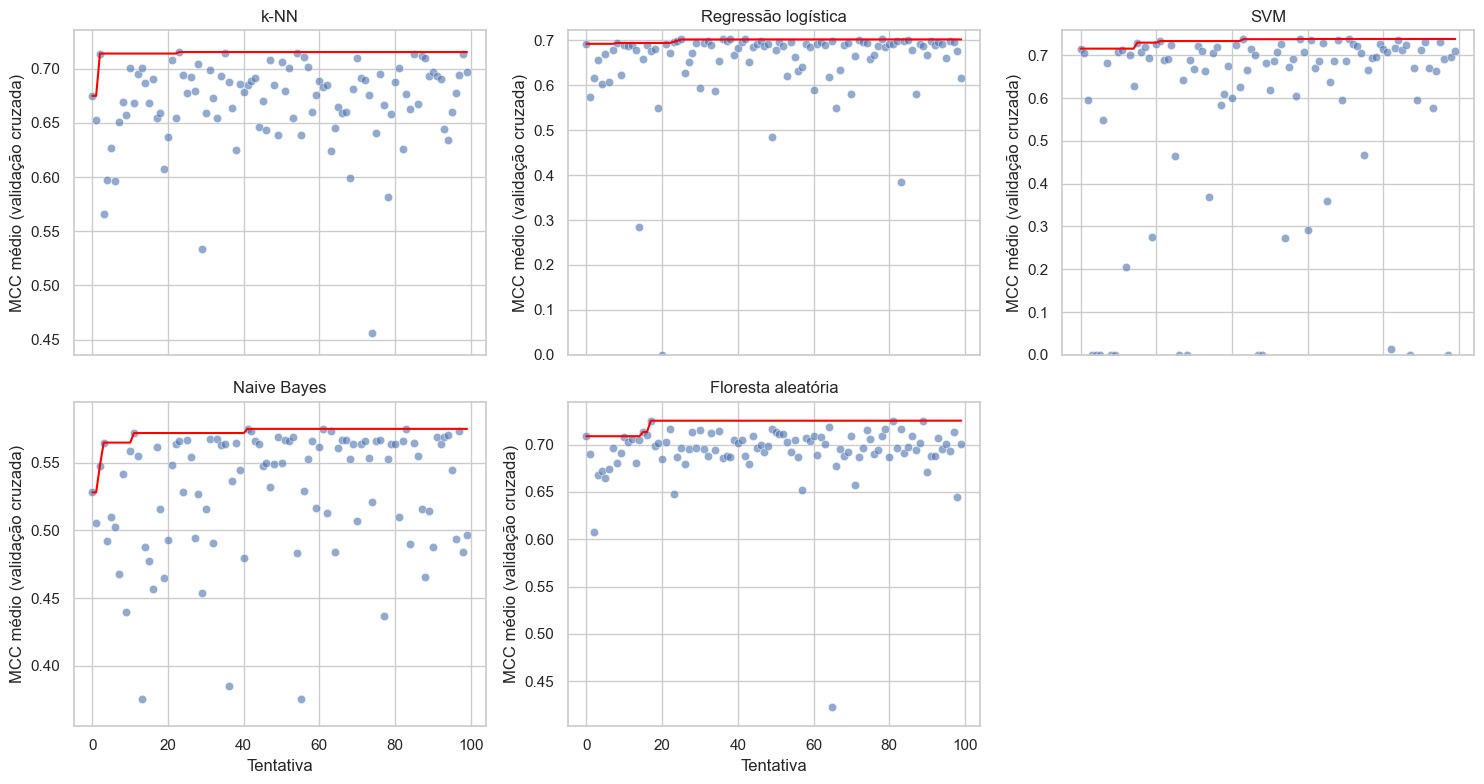

In [34]:
figura, eixos = plt.subplots(2, 3, figsize = (15, 8), sharex = True)
eixos = eixos.ravel()

for eixo, (algoritmo, estudo) in zip(eixos, estudos.items()):
    df_trials = estudo.trials_dataframe()
    df_trials = df_trials[df_trials["state"] == "COMPLETE"]
    melhor_ate_agora = df_trials["value"].cummax()

    sns.scatterplot(x = df_trials["number"], y = df_trials["value"], alpha = 0.6, ax = eixo)
    sns.lineplot(x = df_trials["number"], y = melhor_ate_agora, color = "red", ax = eixo)
    rotula(eixo, "Tentativa", "MCC médio (validação cruzada)", algoritmo)
    eixo.set_ylim(max(0.0, df_trials["value"].min() - 0.02), df_trials["value"].max() + 0.02)

# remove os eixos que sobraram (6 painéis para 5 algoritmos)
for eixo in eixos[len(estudos):]:
    figura.delaxes(eixo)

figura.tight_layout()
salva_figura(figura, "08_historico_otimizacao")

Vamos agora analisar o ganho de otimização sobre a configuração padrão:

In [35]:
ganho = pd.DataFrame(
    {
        algoritmo: {
            "MCC configuração padrão": estudo.trials[0].value,
            "MCC melhor tentativa": estudo.best_value,
        }
        for algoritmo, estudo in estudos.items()
    }
).T
ganho["Ganho"] = ganho["MCC melhor tentativa"] - ganho["MCC configuração padrão"]
ganho.round(3)

,MCC configuração padrão,MCC melhor tentativa,Ganho
k-NN,0.675,0.715,0.040
Regressão logística,0.692,0.702,0.010
SVM,0.715,0.738,0.023
Naive Bayes,0.528,0.575,0.047
Floresta aleatória,0.709,0.725,0.016


Podemos observar que todos os estudos completaram as 100 tentativas sem nenhuma poda. O ganho do `optuna` sobre a configuração padrão (tentativa 0) varia bastante entre os algoritmos: é pequeno na regressão logística (+0,010), na floresta aleatória (+0,016) e no SVM (+0,023), intermediário no k-NN (+0,040) e no Naive Bayes (+0,047). Em todos os algoritmos a linha vermelha sobe nas primeiras dezenas de tentativas e depois quase não muda; ou seja, 100 tentativas bastam para esse espaço de busca. O fato de as configurações padrão, exceto a do Naive Bayes, já terem MCC entre 0,67 e 0,72 sugere que o limite está mais nos dados (41 descritores e 840 exemplos de treino) do que nos hiperparâmetros.

#### 8.3 Quais hiperparâmetros mais importam

O `optuna` estima a importância de cada hiperparâmetro na variação do MCC (aqui com o avaliador baseado em floresta aleatória). Vale ressaltar que hiperparâmetros condicionais, como o `gamma` que só existe para alguns kernels, não entram nessa análise, pois ela só considera parâmetros que estão presentes em todas as tentativas.

Vamos plotar alguns gráficos para termos uma ideia melhor de quais hiperparâmetros mais afetam os nossos algoritmos.

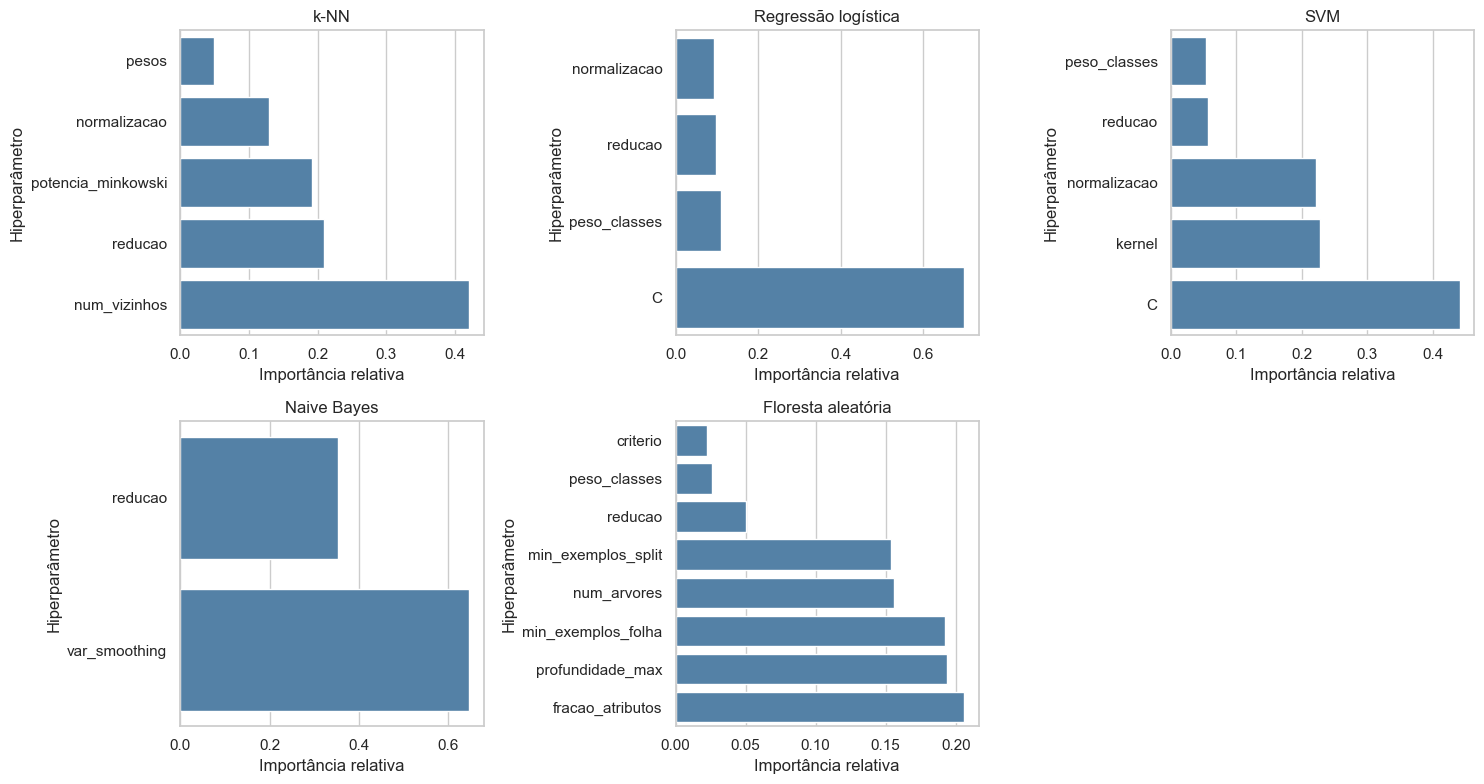

In [36]:
figura, eixos = plt.subplots(2, 3, figsize = (15, 8))

for eixo, (algoritmo, estudo) in zip(eixos.ravel(), estudos.items()):
    importancias = optuna.importance.get_param_importances(
        estudo,
        evaluator = optuna.importance.MeanDecreaseImpurityImportanceEvaluator(seed = SEMENTE_ALEATORIA),
    )
    serie = pd.Series(importancias).sort_values()
    sns.barplot(x = serie.values, y = serie.index, ax = eixo, color = "steelblue")
    rotula(eixo, "Importância relativa", "Hiperparâmetro", algoritmo)

# remove os eixos que sobraram (6 painéis para 5 algoritmos)
for eixo in eixos.ravel()[len(estudos):]:
    figura.delaxes(eixo)

figura.tight_layout()
salva_figura(figura, "09_importancia_hiperparrametro")

Podemos observar que na maioria dos algoritmos, os hiperparâmetros que mais explicam a variação do MCC são os de regularização e complexidade: `C` domina na regressão logística (importância de aproximadamente 0,70) e é o mais importante no SVM (aproximadamente 0,44), seguido do kernel (aproximadamente 0,23) e da normalização (um pouco abaixo de 0,23); no k-NN pesam o número de vizinhos (aproximadamente 0,42), a redução (aproximadamente 0,21) e a potência de Minkowski (aproximadamente 0,19), que é a distância usada; na floresta aleatória, a importância fica espalhada entre `fracao_atributos` (aproximadamente 0,20), `profundidade_max` e `min_exemplos_folha` (ambos em torno de 0,19), seguidos de `num_arvores` e `min_exemplos_split` (em torno de 0,15). No Naive Bayes, `var_smoothing` (aproximadamente 0,65) e a escolha de redução (aproximadamente 0,35) dividem quase toda a importância porque o algoritmo quase não tem outros hiperparâmetros. 

#### 8.4 O que o `optuna` decidiu sobre a redução de dimensionalidade e seleção de atributos

Vamos plotar dois heatmaps: o da esquerda mostra o melhor MCC encontrado para cada algoritmo e estratégia de redução; já o da direita mostra quantas tentativas o TPE dedicou a cada estratégia.

É necessário ter cuidado ao interpretar esses gráficos, visto que o TPE concentra as tentativas nas regiões promissoras, então estratégias com poucas tentativas foram menos exploradas, e não necessariamente piores.

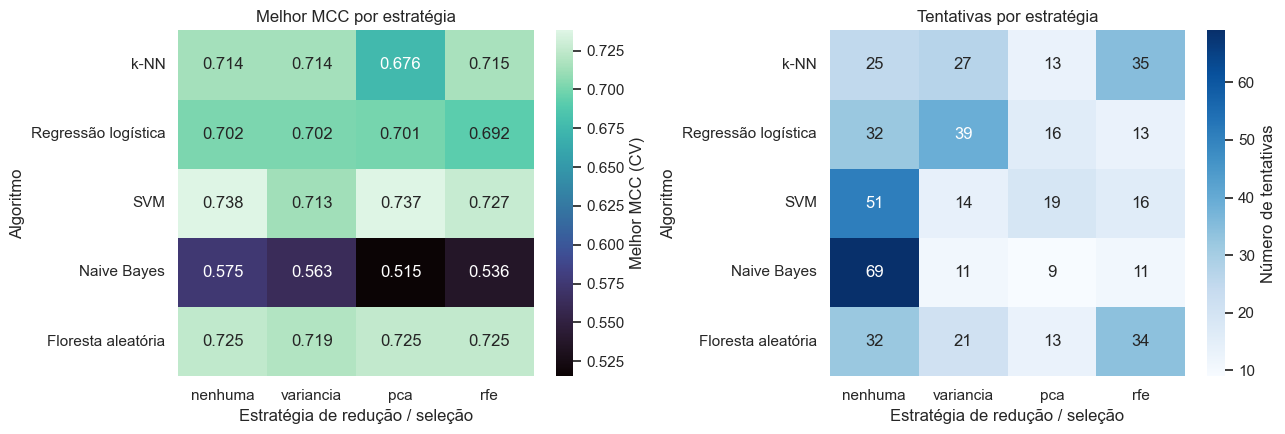

In [37]:
ESTRATEGIAS = ["nenhuma", "variancia", "pca", "rfe"]

melhor_por_reducao = {}
contagem_por_reducao = {}
for algoritmo, estudo in estudos.items():
    df_trials = estudo.trials_dataframe()
    df_trials = df_trials[df_trials["state"] == "COMPLETE"]
    agrupado = df_trials.groupby("params_reducao")["value"]
    melhor_por_reducao[algoritmo] = agrupado.max().reindex(ESTRATEGIAS)
    contagem_por_reducao[algoritmo] = agrupado.size().reindex(ESTRATEGIAS).fillna(0)

df_melhor = pd.DataFrame(melhor_por_reducao).T
df_contagem = pd.DataFrame(contagem_por_reducao).T

figura, eixos = plt.subplots(1, 2, figsize = (13, 4.5))
sns.heatmap(df_melhor, annot = True, fmt = ".3f", cmap = "mako", ax = eixos[0],
           cbar_kws = {"label": "Melhor MCC (CV)"})
rotula(eixos[0], "Estratégia de redução / seleção", "Algoritmo", "Melhor MCC por estratégia")

sns.heatmap(df_contagem, annot = True, fmt = ".0f", cmap = "Blues", ax = eixos[1],
           cbar_kws = {"label": "Número de tentativas"})
rotula(eixos[1], "Estratégia de redução / seleção", "Algoritmo", "Tentativas por estratégia")

figura.tight_layout()
salva_figura(figura, "10_efeito_de_reducao")

Os resultados indicam que a redução de dimensionalidade teve impacto limitado para a maioria dos algoritmos avaliados. Regressão logística e floresta aleatória apresentaram variações muito pequenas de MCC entre as estratégias, e o k-NN só perdeu desempenho de forma notável com o PCA (0,676, contra 0,714 sem redução), sugerindo que o conjunto original de atributos já continha informação suficiente sem gerar prejuízo significativo por redundância. O melhor desempenho obtido foi pelo SVM sem redução de atributos (MCC = 0,738), valor praticamente idêntico ao alcançado com PCA (0,737). 

Em contraste, o Naive Bayes apresentou redução consistente de desempenho após a aplicação das técnicas de seleção ou redução, indicando maior dependência do conjunto completo de atributos.

De modo geral, não foi observada uma vantagem sistemática da redução dimensional, sendo seus benefícios dependentes do algoritmo considerado.

#### 8.5 Melhores configurações encontradas

Após a etapa de otimização de hiperparâmetros usando validação cruzada estratificada e o `optuna`, foram identificadas as configurações que resultaram no melhor desempenho para cada algoritmo avaliado. Nessa seção, os melhores hiperparâmetros encontrados são organizados em uma única estrutura, permitindo tanto o armazenamento dos resultados em formato JSON quanto a sua visualização tabular para análises e comparações posteriores.

O objetivo dessa etapa é registrar de forma reprodutível as configurações ótimas obtidas durante o processo de busca, garantindo que os modelos finais possam ser reconstruídos exatamente com os parâmetros que produziram os melhores resultados experimentais.

In [38]:
melhores_hiperparametros = {
    algoritmo: {"MCC_CV_optuna": estudo.best_value, **estudo.best_params}
    for algoritmo, estudo in estudos.items()
}

with open(DIR_RESULTADOS / "melhores_hiperparametros.json", "w", encoding = "utf-8") as arquivo:
    json.dump(melhores_hiperparametros, arquivo, indent = 2, ensure_ascii = False, default = str)

pd.DataFrame(melhores_hiperparametros).T.drop(columns = "MCC_CV_optuna").dropna(axis = 1, how = "all")

,num_vizinhos,pesos,potencia_minkowski,reducao,normalizacao,rfe_num_atributos,rfe_passo,C,peso_classes,limiar_variancia,kernel,gamma,var_smoothing,num_arvores,criterio,profundidade_max,min_exemplos_split,min_exemplos_folha,fracao_atributos
k-NN,17,distance,1.162734,rfe,padrao,36,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Regressão logística,NaN,NaN,NaN,variancia,padrao,NaN,NaN,1.877155,None,0.000235,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SVM,NaN,NaN,NaN,nenhuma,padrao,NaN,NaN,4.845954,balanced,NaN,rbf,0.04404,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Naive Bayes,NaN,NaN,NaN,nenhuma,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000148,NaN,NaN,NaN,NaN,NaN,NaN
Floresta aleatória,NaN,NaN,NaN,rfe,NaN,33,3,NaN,balanced_subsample,NaN,NaN,NaN,NaN,58,gini,40,4,1,0.173


A tabela apresentada resume os hiperparâmetros considerados ótimos para cada algoritmo após o processo de otimização. Observa-se que as diferentes técnicas de aprendizagem demandaram estratégias distintas de pré-processamento, seleção de atributos e ajuste de hiperparâmetros para atingir seu melhor desempenho.

Para o algoritmo k-NN, o melhor desempenho foi obtido utilizando 17 vizinhos, ponderação por distância, métrica de Minkowski com potência de aproximadamente 1,16. Além disso, a melhor configuração usou RFE para a seleção de atributos, mantendo 36 variáveis, juntamente com a normalização padrão dos dados. Como o RFE manteve 36 dos 41 descritores e a configuração sem redução alcançou praticamente o mesmo MCC (0,714 contra 0,715, seção 8.4), o ganho vem do ajuste de k, da ponderação e da potência de Minkowski, e não da seleção de atributos. A potência próxima de 1 (distância de Manhattan) é consistente com a recomendação para dados de alta dimensionalidade.

A regressão logística apresentou melhor desempenho quando combinada com a normalização padrão dos atributos e uma etapa de remoção de características baseada em limiar de variância (Variance Threshold), utilizando um valor de corte de aproximadamente 0,000235. O parâmetro de regularização encontrado foi C = 1,877, próximo do valor padrão (C = 1), o que combina com o ganho pequeno da otimização nesse algoritmo (+0,010). Esse limiar é menor que a menor variância min-max observada entre os descritores (cerca de 0,0027), então, na prática, nenhum atributo (ou quase nenhum) é removido, e o MCC dessa configuração é o mesmo da regressão logística sem redução (0,702, seção 8.4). Ou seja, a redução de dimensionalidade não trouxe ganho para esse algoritmo.

Para o modelo SVM, a combinação ótima envolveu a normalização padrão dos dados, utilizando o kernel RBF (Radial Basis Function), parâmetro de regularização C = 4,846 e valor de `gamma` igual a 0,044. Adicionalmente, foi empregado o esquema de balanceamento de classes (`class_weight` = `balanced`), indicando que o conjunto de dados possui alguma assimetria entre as classes e que a compensação dos pesos contribuiu para melhorar a capacidade de generalização do modelo. O uso do kernel RBF demonstra que relações não lineares entre os atributos e as classes são importantes para a tarefa em estudo.

O Naive Bayes obteve melhor resultado sem a necessidade de etapas adicionais de redução de dimensionalidade ou normalização, sendo `var_smoothing` igual a 0,000148 o principal hiperparâmetro. Esse parâmetro controla a estabilidade numérica durante a estimativa das distribuições de probabilidade e sua otimização permite tornar o modelo mais robusto a variâncias muito pequenas nos atributos. 

Por último, a floresta aleatória alcançou o melhor desempenho utilizando o método RFE para a seleção de atributos, mantendo 33 características relevantes. O modelo foi configurado com 58 árvores de decisão, critério baseado no índice `gini`, profundidade máxima de 40 níveis, número mínimo de 4 amostras para a divisão de um nó, número mínimo de 1 amostra por folha e utilização de aproximadamente 17,3% dos atributos em cada divisão. Além disso, foi aplicado o `balanced_subsample` para compensação do desbalanceamento entre as classes. Esses resultados indicam que árvores profundas (profundidade máxima 40, praticamente sem limite) e com forte aleatorização dos atributos em cada divisão funcionaram bem; vale notar que o RFE empatou com a configuração sem redução (0,725 em ambos, seção 8.4). 

De modo geral, a normalização foi obrigatória para os modelos sensíveis à escala (k-NN, regressão logística e SVM), enquanto a floresta aleatória e o Naive Bayes dispensam esse passo. Na floresta aleatória, o ajuste da complexidade das árvores (profundidade, tamanho mínimo de folha e fração de atributos por divisão) pesou mais do que a seleção de atributos, como mostram as importâncias da seção 8.3 e o empate com a configuração sem redução (seção 8.4). Esses resultados reforçam a importância da otimização sistemática dos hiperparâmetros, uma vez que cada algoritmo apresentou requisitos específicos para atingir seu melhor desempenho, não existindo uma configuração universal ótima para todos os métodos avaliados.

### 9. Comparando os algoritmos

#### 9.1 O que será feito

O melhor MCC que o `optuna` registrou é otimista, sendo ele o máximo entre 100 tentativas avaliadas nos mesmos 5 folds, então parte do resultado é sorte nas partições usadas (viés de seleção [13]). Para comparar os algoritmos de forma justa, reavaliamos o melhor pipeline de cada algoritmo (e o baseline) com validação cruzada repetida em partições novas: 5 repetições de `StratifiedGroupKFold` com sementes diferentes, ou seja, 25 valores de MCC por algoritmo, todos com as mesmas partições.

Isso continua usando apenas o conjunto de treino. O "campeão" é o algoritmo com maior MCC médio nessa comparação, escolhido antes de olhar o teste.

In [39]:
def cv_repetido(modelo, X, y, grupos, sementes):
    """MCC em validação cruzada repetida, estratificada e agrupada"""

    valores = []
    for semente in sementes:
        particoes = list(
            StratifiedGroupKFold(
                n_splits = NUM_FOLDS, shuffle = True, random_state = semente
            ).split(X, y, groups = grupos)
        )
        valores += cross_val_score(
            modelo, X, y, cv = particoes, scoring = "matthews_corrcoef"
        ).tolist()

    return np.array(valores)

In [40]:
# pipelines com os melhores hiperparâmtros de cada estudo (ainda sem treinar)
MODELOS_FINAIS = {
    algoritmo: ALGORITMOS[algoritmo](estudo.best_trial)
    for algoritmo, estudo in estudos.items()
}

linhas = []
for algoritmo, modelo in {"Baseline": modelo_baseline, **MODELOS_FINAIS}.items():
    valores = cv_repetido(modelo, X_treino, y_treino, grupos_treino, SEMENTES_CV_REPETIDO)
    linhas += [
        {"Algoritmo": algoritmo, "Partições": i, "MCC": v} for i, v in enumerate(valores)
    ]

df_cv = pd.DataFrame(linhas)

tabela_cv = (
    df_cv.groupby("Algoritmo")["MCC"].agg(["mean", "std", "min", "max"])
    .rename(columns = {"mean": "MCC médio", "std": "Desvio padrão", "min": "Mínimo", "max": "Máximo"})
    .sort_values("MCC médio", ascending = False)
)
tabela_cv["MCC melhor tentativa (optuna)"] = [
    estudos[a].best_value if a in estudos else np.nan for a in tabela_cv.index
]
tabela_cv.to_csv(DIR_RESULTADOS / "comparacao_cv_repetida.csv")
tabela_cv.round(3)

,MCC médio,Desvio padrão,Mínimo,Máximo,MCC melhor tentativa (optuna)
Algoritmo,,,,,
SVM,0.739,0.052,0.629,0.846,0.738
Floresta aleatória,0.715,0.048,0.618,0.800,0.725
k-NN,0.696,0.052,0.583,0.786,0.715
Regressão logística,0.695,0.057,0.560,0.807,0.702
Naive Bayes,0.564,0.036,0.481,0.628,0.575
Baseline,0.000,0.000,0.000,0.000,NaN


Campeão (escolhido apenas com dados de treino): SVM


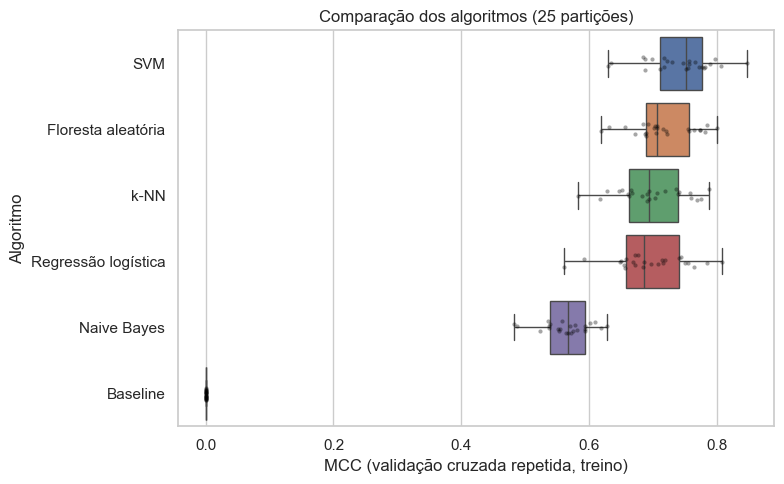

In [41]:
ordem = tabela_cv.index.tolist()

figura, eixo = plt.subplots(figsize = (8, 5))
sns.boxplot(data = df_cv, x = "MCC", y = "Algoritmo", order = ordem, hue = "Algoritmo",
           hue_order = ordem, legend = False, ax = eixo)
sns.stripplot(data = df_cv, x = "MCC", y = "Algoritmo", order = ordem, color = "black",
             alpha = 0.35, size = 3, ax = eixo)
rotula(eixo, "MCC (validação cruzada repetida, treino)", "Algoritmo",
      "Comparação dos algoritmos (25 partições)")
figura.tight_layout()
salva_figura(figura, "11_comparacao_cv_repetida")

# escolha do "campeão": maior MCC médio na CV repetida, excluindo o baseline
CAMPEAO = tabela_cv.drop(index = "Baseline")["MCC médio"].idxmax()
print(f"Campeão (escolhido apenas com dados de treino): {CAMPEAO}")

In [42]:
# diferença pareada entre cada algoritmo e o campeão nas mesmas 25 partições
mcc_por_algoritmo = df_cv.pivot(index = "Partições", columns = "Algoritmo", values = "MCC")

diferencas = pd.DataFrame(
    {
        "Diferença média para o campeão": (mcc_por_algoritmo.sub(mcc_por_algoritmo[CAMPEAO], axis = 0)).mean(),
        "Desvio padrão da diferença": (mcc_por_algoritmo.sub(mcc_por_algoritmo[CAMPEAO], axis = 0)).std(),
        "Partições em que supera o campeão": (mcc_por_algoritmo.gt(mcc_por_algoritmo[CAMPEAO], axis = 0)).sum(),
    }
).drop(index = CAMPEAO).sort_values("Diferença média para o campeão", ascending = False)
diferencas.round(3)

,Diferença média para o campeão,Desvio padrão da diferença,Partições em que supera o campeão
Algoritmo,,,
Floresta aleatória,-0.025,0.058,9
k-NN,-0.043,0.055,7
Regressão logística,-0.045,0.061,4
Naive Bayes,-0.176,0.062,0
Baseline,-0.739,0.052,0


Cada linha da tabela compara um algoritmo com o campeão, o SVM, nas mesmas 25 partições da validação cruzada repetida (5 repetições x 5 folds). Em cada partição calculamos `MCC do algoritmo - MCC do SVM` e resumimos o resultado em três colunas:

- Diferença média para o campeão: quanto, em média, o algoritmo fica acima ou abaixo do SVM, de modo que valores negativos indicam um desempenho pior e quanto mais negativo maior a distância;
- Desvio padrão da diferença: quanto essa diferença varia de uma partição para outra, de modo que um desvio grande significa que o resultado depende bastante da partição sorteada;
- Partições em que supera o campeão: em quantas das 25 partições o algoritmo obteve MCC maior que o SVM

Vale ressaltar que o SVM não aparece como linha porque ele é a referência usada, de modo que sua diferença com ele mesmo seria sempre zero. 

Agora ao debater os resultados, podemos observar:

- O SVM é o campeão: ele tem o maior MCC médio na validação cruzada repetida (0,739), e os demais ficam para trás, na ordem: floresta aleatória (0,715), k-NN (0,696), regressão logística (0,695) e Naive Bayes (0,564). A escolha usou apenas dados de treino;
- A floresta aleatória "chega perto": em média fica só 0,025 abaixo do SVM, e supera o SVM em 9 das 25 partições. Como a variação entre partições (desvio de 0,058) é maior que essa diferença média, a vantagem do SVM sobre eles é pequena e não deve ser tratada como definitiva;
- k-NN e regressão logística ficam um pouco mais atrás: a diferença média sobe cerca de 0,04 e eles superam o SVM em apenas 7 e 4 partições, respectivamente. A vantagem do SVM sobre eles é mais consistente;
- Naive Bayes e baseline ficam bem abaixo: o Naive Bayes fica 0,176 abaixo e nunca supera o SVM. O baseline também nunca supera o SVM; como o MCC dele é sempre 0, a diferença média (-0,739) é simplesmente o MCC médio do SVM com sinal invertido, e o desvio da diferença (0,052) é o próprio desvio do MCC do SVM.

Assim, podemos concluir que o SVM (kernel RBF, `C` aproximadamente 4,85, `gamma` aproximadamente 0,044, normalização com `StandardScaler`, pesos de classe balanceados e sem redução de dimensionalidade) é o melhor algoritmo no treino e segue para a avaliação final no teste.

### 10. Avaliação final no conjunto teste

#### 10.1 O que será feito

Agora, uma única vez, ajustamos cada pipeline com os melhores hiperparâmetros no treino completo e avaliamos no teste. O campeão já foi definido anteriormente, apenas com dados de treino; o teste serve apenas para estimar o desempenho em substâncias novas, não para escolher modelos.

Como o teste tem só 215 substâncias, a estimativa de MCC tem incerteza considerável. Por isso reportamos também um intervalo de confiança de 95% por bootstrap [17]: sorteamos, com reposição, 2000 conjuntos de teste do mesmo tamanho a partir das previsões e calculamos o MCC em cada um.

Vamos começar criando funções auxiliares: `pontuacao` extrai de cada modelo um valor contínuo para a classe RB (probabilidade ou distância à fronteira de decisão), necessário para as curvas ROC e PR. `metricas_classificacao` calcula as oito métricas que vamos reportar, e `intervalo_bootstrap_mcc` calcula o intervalo de confiança de 95% descrito acima.

Logo em seguida será plotada uma tabela reunindo as métricas e o intervalo de confiança de todos os algoritmos.

In [43]:
def pontuacao(modelo, X):
    """Pontuação contínua da classe positiva (RB), para curvas ROC e PR"""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)

In [44]:
def metricas_classificacao(y_verdadeiro, y_previsto, y_pontuacao):
    """As oito métricas de classificação reportadas no teste"""
    return {
        "MCC": matthews_corrcoef(y_verdadeiro, y_previsto),
        "Acurácia": accuracy_score(y_verdadeiro, y_previsto),
        "Acurácia balanceada": balanced_accuracy_score(y_verdadeiro, y_previsto),
        "F1 (RB)": f1_score(y_verdadeiro, y_previsto),
        "Precisão (RB)": precision_score(y_verdadeiro, y_previsto, zero_division = 0),
        "Revocação (RB)": recall_score(y_verdadeiro, y_previsto),
        "AUC-ROC": roc_auc_score(y_verdadeiro, y_pontuacao),
        "AUC-PR": average_precision_score(y_verdadeiro, y_pontuacao),
    }

In [45]:
def intervalo_bootstrap_mcc(y_verdadeiro, y_previsto, repeticoes, semente):
    """Intervalo de confiança de 95% do MCC por bootstrap"""
    gerador = np.random.default_rng(semente)
    y_verdadeiro, y_previsto = np.asarray(y_verdadeiro), np.asarray(y_previsto)
    n = len(y_verdadeiro)
    valores = []

    for _ in range(repeticoes):
        indices = gerador.integers(0, n, size = n)
        valores.append(matthews_corrcoef(y_verdadeiro[indices], y_previsto[indices]))
    return np.percentile(valores, [2.5, 97.5])

In [46]:
modelos_teste = {"Baseline": modelo_baseline, **MODELOS_FINAIS}

previsoes_teste = {}
linhas = []
for nome, modelo in modelos_teste.items():
    modelo.fit(X_treino, y_treino)
    y_previsto = modelo.predict(X_teste)
    y_pontuacao = pontuacao(modelo, X_teste)
    previsoes_teste[nome] = (y_previsto, y_pontuacao)

    metricas = metricas_classificacao(y_teste, y_previsto, y_pontuacao)
    ic_baixo, ic_alto = intervalo_bootstrap_mcc(
        y_teste, y_previsto, NUM_REPETICOES_BOOTSTRAP, SEMENTE_ALEATORIA
    )
    linhas.append({"Algoritmo": nome, **metricas, "MCC IC95% inf.": ic_baixo, "MCC IC95% sup.": ic_alto})

tabela_teste = pd.DataFrame(linhas).set_index("Algoritmo").sort_values("MCC", ascending = False)
tabela_teste.to_csv(DIR_RESULTADOS / "avaliacao_teste.csv")
tabela_teste.round(3)

,MCC,Acurácia,Acurácia balanceada,F1 (RB),Precisão (RB),Revocação (RB),AUC-ROC,AUC-PR,MCC IC95% inf.,MCC IC95% sup.
Algoritmo,,,,,,,,,,
SVM,0.662,0.847,0.850,0.766,0.692,0.857,0.920,0.817,0.555,0.756
Regressão logística,0.656,0.851,0.839,0.761,0.718,0.810,0.921,0.803,0.540,0.756
Floresta aleatória,0.644,0.842,0.837,0.754,0.693,0.825,0.921,0.839,0.529,0.750
k-NN,0.641,0.837,0.838,0.752,0.679,0.841,0.919,0.815,0.529,0.742
Naive Bayes,0.533,0.740,0.793,0.674,0.532,0.921,0.889,0.709,0.436,0.626
Baseline,0.000,0.707,0.500,0.000,0.000,0.000,0.500,0.293,0.000,0.000


A tabela mostra que quatro modelos ficam praticamente empatados no topo: SVM (0,662), regressão logística (0,656), floresta aleatória (0,644) e k-NN (0,641). Os intervalos de confiança deles se sobrepõem quase totalmente (cerca de 0,53 a 0,76), então as diferenças de poucos centésimos estão dentro do ruído de um teste com 215 substâncias. O Naive Bayes fica claramente abaixo (MCC 0,533), com revocação alta de RB (0,921) e precisão baixa (0,532). O baseline tem MCC 0 e AUC-ROC 0,5, como esperado de um modelo que só prevê a classe majoritária.

Agora iremos comparar, para cada algoritmo, o MCC obtido no teste (barras azuis, com o intervalo de confiança de 95% como barra de erro) com o MCC médio da validação cruzada repetida (pontos vermelhos). O objetivo é verificar se o desempenho estimado no treino se sustenta em dados que o modelo nunca viu. Um ponto vermelho bem à direita da barra indicaria otimismo da validação.

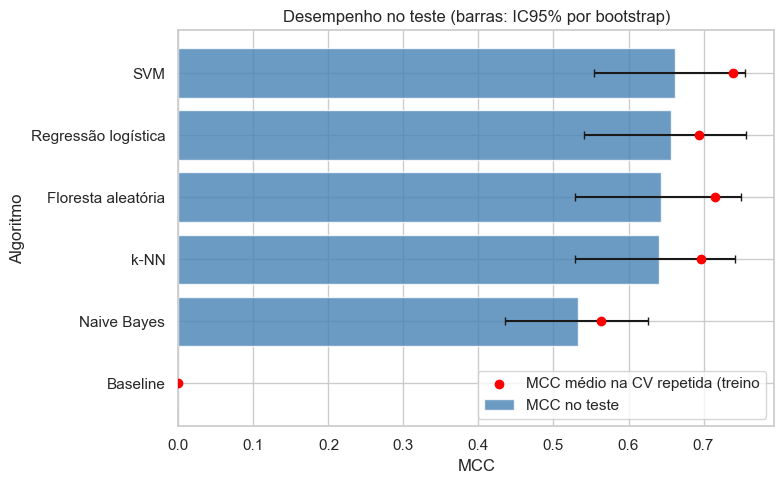

In [47]:
ordem_teste = tabela_teste.index.tolist()
mcc_cv_medio = tabela_cv["MCC médio"].reindex(ordem_teste)

figura, eixo = plt.subplots(figsize = (8, 5))
posicoes = np.arange(len(ordem_teste))
eixo.barh(
    posicoes, tabela_teste["MCC"], color = "steelblue", alpha = 0.8, label = "MCC no teste", xerr = [
        tabela_teste["MCC"] - tabela_teste["MCC IC95% inf."],
        tabela_teste["MCC IC95% sup."] - tabela_teste["MCC"],
    ],
    capsize = 3,
)
eixo.scatter(mcc_cv_medio, posicoes, color = "red", zorder = 3, label = "MCC médio na CV repetida (treino)")
eixo.set_yticks(posicoes, ordem_teste)
eixo.invert_yaxis()
eixo.legend(loc = "lower right")
rotula(eixo, "MCC", "Algoritmo", "Desempenho no teste (barras: IC95% por bootstrap)")
figura.tight_layout()
salva_figura(figura, "12_desempenho_no_teste")

Em todos os algoritmos o ponto vermelho (CV) está à direita da barra (teste), ou seja, todos os modelos pioraram um pouco no teste. A queda vai de 0,031 (Naive Bayes) a 0,077 (SVM). Como a queda aparece em todos os modelos, ela provavelmente vem do próprio conjunto de teste, que tem menos RB (29,3% contra 34,9% no treino) e inclui uma substância muito distante do treino (seção 4.3), além do viés de seleção da CV. Não parece um defeito do campeão. Em quase todos os casos o valor da CV cai dentro ou muito perto do intervalo de confiança do teste, o que é compatível com a incerteza de uma amostra pequena.

Agora, a célula a seguir mostra os acertos do modelo campeão (SVM) no teste. O painel da esquerda traz as contagens e o da direita traz a fração por classe real, ou seja, cada linha é dividida pelo seu total, o que dá taxa de acertos em cada classe independentemente do desbalanceamento. Isso permite ver onde o modelo erra, algo que o MCC sozinho não mostra.

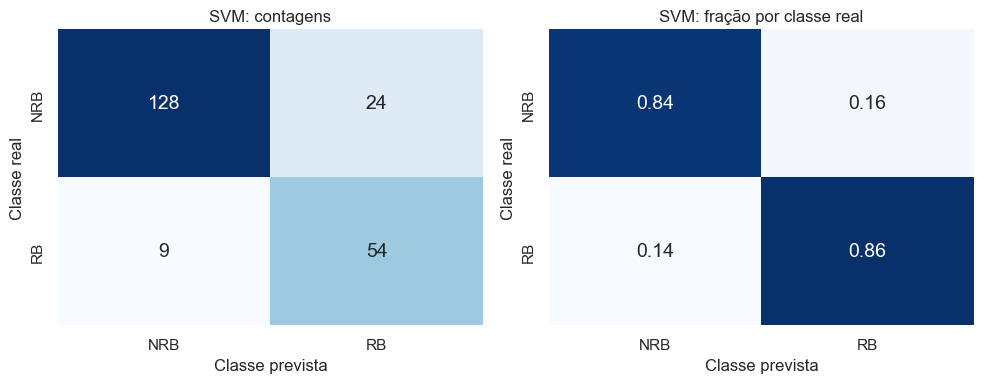

In [49]:
y_previsto_campeao, y_pontuacao_campeao = previsoes_teste[CAMPEAO]
matriz = confusion_matrix(y_teste, y_previsto_campeao, labels = [0, 1])
matriz_normalizada = matriz / matriz.sum(axis = 1, keepdims = True)
rotulos = [NOME_CLASSE[0], NOME_CLASSE[1]]

figura, eixos = plt.subplots(1, 2, figsize = (10, 4))
for eixo, dados, formato, titulo in [
    (eixos[0], matriz, "d", f"{CAMPEAO}: contagens"),
    (eixos[1], matriz_normalizada, ".2f", f"{CAMPEAO}: fração por classe real"),
]:
    sns.heatmap(dados, annot = True, fmt = formato, cmap = "Blues", cbar = False,
               xticklabels = rotulos, yticklabels = rotulos, annot_kws = {"size": 14}, ax = eixo)
    rotula(eixo, "Classe prevista", "Classe real", titulo)
figura.tight_layout()
salva_figura(figura, "13_matriz_de_confusao_campeao")

Das 152 substâncias NRB reais, o SVM acerta 128 (84%) e erra 24. Das 63 substâncias RB reais, acerta 54 (86%) e erra 9. O erro mais comum é prever RB para uma substância que é NRB (24 casos), e é ele que explica a precisão de apenas 69% para RB. Em triagem ambiental esse é o erro mais perigoso, pois uma substância persistente seria considerada biodegradável. Isso pode estar ligado aos pesos de classe balanceados do SVM, que favorecem a revocação da classe minoritária (RB) à custa da precisão.

A célula a seguir traça duas curvas para todos os modelos, com o campeão em linha mais grossa. A curva ROC (esquerda) mostra a taxa de verdadeiros positivos contra a de falsos positivos conforme variamos o limiar de decisão. A curva precisão-revocação (direita) mostra a precisão contra a revocação para a classe RB, e é mais informativa quando as classes são desbalanceadas. As linhas tracejadas indicam o desempenho de um classificador sem poder preditivo (o baseline). Diferentemente do MCC, essas curvas não dependem de um limiar fixo, então avaliam a capacidade de ordenar as substâncias.

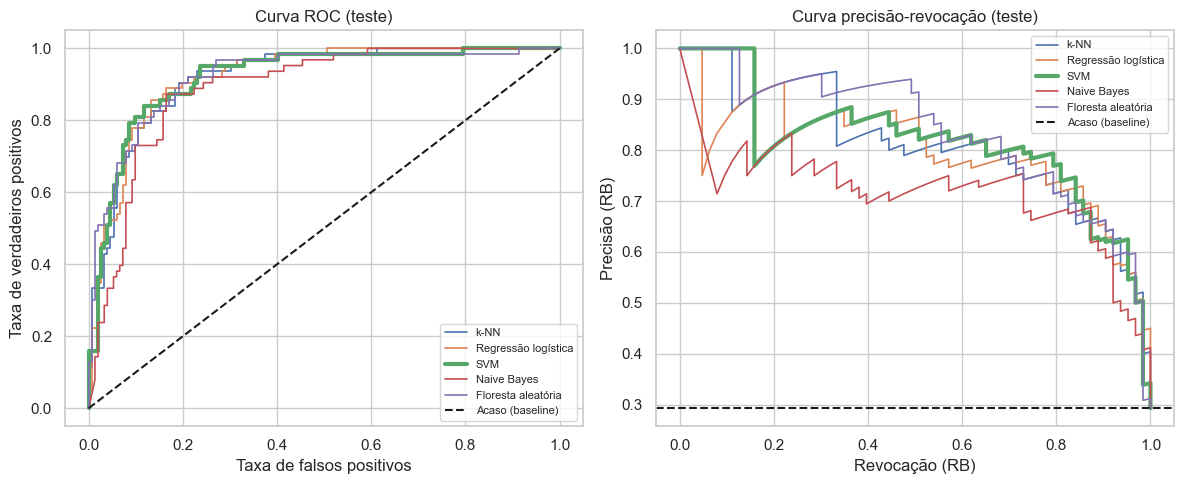

In [50]:
figura, eixos = plt.subplots(1, 2, figsize = (12, 5))

for nome, (_, y_pontuacao) in previsoes_teste.items():
    if nome == "Baseline":
        continue
    largura = 3 if nome == CAMPEAO else 1.2
    fpr, tpr, _ = roc_curve(y_teste, y_pontuacao)
    eixos[0].plot(fpr, tpr, linewidth = largura, label = nome)
    precisao, revocacao, _ = precision_recall_curve(y_teste, y_pontuacao)
    eixos[1].plot(revocacao, precisao, linewidth = largura, label = nome)

eixos[0].plot([0, 1], [0, 1], "k--", label = "Acaso (baseline)")
eixos[1].axhline(y_teste.mean(), color = "k", linestyle = "--", label = "Acaso (baseline)")
rotula(eixos[0], "Taxa de falsos positivos", "Taxa de verdadeiros positivos", "Curva ROC (teste)")
rotula(eixos[1], "Revocação (RB)", "Precisão (RB)", "Curva precisão-revocação (teste)")
eixos[0].legend(fontsize = 8)
eixos[1].legend(fontsize = 8)
figura.tight_layout()
salva_figura(figura, "14_curvas_roc_e_pr")

Todos os modelos, exceto o Naive Bayes, têm curvas ROC quase sobrepostas e bem acima da diagonal, com AUC-ROC em torno de 0,92. Na curva precisão-revocação o comportamento é  parecido, com AUC-PR entre 0,80 e 0,84, muito acima do valor de acaso (0,293, a proporção de RB no teste). O Naive Bayes fica abaixo dos demais nas duas curvas (AUC-ROC 0,889; AUC-PR 0,709). Ou seja, os quatro melhores modelos têm praticamente a mesma capacidade de separar RB e NRB, e as diferenças de MCC entre eles vêm sobretudo da escolha do limiar de decisão.

### 11. Explicando o modelo campeão

#### 11.1 O que será feito

Usaremos duas ferramentas de explicação, ambas aplicadas ao pipeline completo (então as explicações são sempre em termos dos 41 descritores originais, mesmo que o pipeline reduza a dimensionalidade internamente).

A *permutation importance* [6] mede o quanto o desempenho do modelo piora quando os valores de um descritor são embaralhados (permutados) no conjunto teste, o que quebra a relação entre o descritor e o target sem mexer no resto. Se o MCC cai muito, o modelo dependia daquele descritor. Repetimos o embaralhamento 30 vezes para estimar a variabilidade. Temos ainda uma limitação: com descritores correlacionados, o modelo pode compensar a perda de um deles usando o outro, e a importância do grupo fica "diluída".

O SHAP [8] baseia-se nos valores de Shapley da teoria dos jogos cooperativos: a previsão do modelo para um exemplo é decomposta em uma soma de contribuições, uma por descritor,

$$f(x) = \phi_0 + \sum_{j=1}^{41} \phi_j(x)$$

em que $\phi_0$ é a previsão média sobre os dados de fundo e $\phi_j(x)$ é a contribuição do descritor $j$ para aquele exemplo. A contribuição $\phi_j$ é a média do efeito de "ligar" o descritor $j$ sobre todas as ordens possíveis em que os descritores podem ser revelados ao modelo. Como calcular exatamente seria inviável, usamos o `PermutationExplainer` do SHAP, que aproxima essa média sorteando permutações de descritores; os descritores ausentes são substituídos por valores de fundo (40 substâncias do treino). Explicamos 60 substâncias do teste. Valores SHAP positivos empurram a previsão para RB e negativos para NRB. Como o SVM campeão não fornece probabilidades, a "previsão" explicada aqui é a função de decisão do SVM (distância com sinal até a fronteira de decisão), e os valores SHAP estão nessa escala, e não em probabilidade. Diferente da *Permutation Importance* (importância global), o SHAP explica cada previsão e também mostra a direção do efeito. 

A célula a seguir calcula a importância por permutação do SVM campeão no conjunto de teste. Para cada um dos 41 descritores, embaralhamos seus valores 30 vezes e medimos quanto o MCC cai, de modo que quanto maior a queda, mais o modelo dependia daquele descritor. A célula produz duas saídas: uma tabela com os 10 primeiros, acompanhados de uma descrição química de cada um e um gráfico de barras com os 15 descritores mais importantes (as barras de erro são o desvio padrão das 30 repetições).

,Descritor,Queda média do MCC,Desvio padrão,Descrição
37,nN,0.0928,0.0460,número de átomos de nitrogênio
19,nArNO2,0.0756,0.0215,número de grupos nitro aromáticos
36,Psi_i_A,0.0508,0.0227,índice de pseudoconectividade de estado intrín...
9,nO,0.0403,0.0297,número de átomos de oxigênio
21,SpPosA_B(p),0.0285,0.0182,"soma espectral positiva normalizada (Burden, p..."
31,nCrt,0.0284,0.0203,número de C(sp3) terciários em anel
4,F04_C-N,0.0260,0.0205,frequência de pares C-N a distância topológica 4
2,nHM,0.0225,0.0241,número de átomos pesados
30,TI2_L,0.0225,0.0189,segundo índice do Mohar (matriz Laplaciana)
11,SdssC,0.0201,0.0158,soma dos E-states dssC


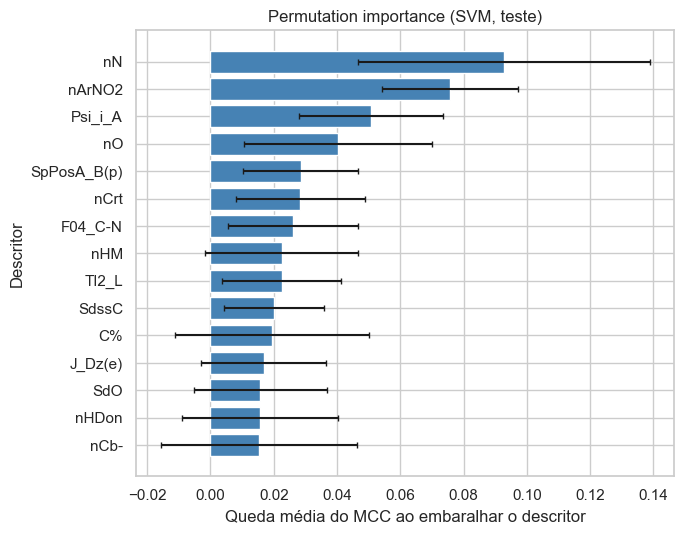

In [54]:
campeao_modelo = MODELOS_FINAIS[CAMPEAO]

resultado_pi = permutation_importance(
    campeao_modelo, X_teste, y_teste, scoring = "matthews_corrcoef",
    n_repeats = 30, random_state = SEMENTE_ALEATORIA,
)
df_pi = pd.DataFrame(
    {
        "Descritor": X_teste.columns,
        "Queda média do MCC": resultado_pi.importances_mean,
        "Desvio padrão": resultado_pi.importances_std,
    }
).sort_values("Queda média do MCC", ascending = False)

top_pi = df_pi.head(15).iloc[::-1]
figura, eixo = plt.subplots(figsize = (7, 5.5))
eixo.barh(top_pi["Descritor"], top_pi["Queda média do MCC"], xerr = top_pi["Desvio padrão"],
         color = "steelblue", capsize = 2)
rotula(eixo, "Queda média do MCC ao embaralhar o descritor", "Descritor",
      f"Permutation importance ({CAMPEAO}, teste)")
figura.tight_layout()
salva_figura(figura, "15_permutation_importance")

df_pi.head(10).assign(Descrição = lambda d: d["Descritor"].map(DESCRICAO)).round(4)

A tabela nos confirma os valores do gráfico e mostra o que cada descritor representa. Vários dos mais importantes são contagens simples de átomos ou grupos (`nN`, `nO`, `nHM`, `nArNO2`, `nCrt`), fáceis de interpretar quimicamente. Outros são índices topológicos (`Psi_i_A`, `SpPosA_B(p)`, `TI2_L`), cuja interpretação é menos direta.

Já com o gráfico, observamos que o descritor mais importante é `nN` (número de átomos de nitrogênio), cujo embaralhamento derruba o MCC em cerca de 0,09. Em seguida vem `nArNO2` (grupos nitro aromáticos), `Psi_i_A` e `nO` (número de átomos de oxigênio). Depois desses quatro, as importâncias caem para valores próximos de 0,02 e 0,03 e as barras de erro se sobrepõem em vários descritores. Só os primeiros colocados se destacam com alguma segurança, e a ordem dos demais é incerta. 

A seguir, iremos calcular os valores de SHAP do SVM para 60 substâncias do teste. A função `preve_modelo` encapsula o pipeline para o SHAP poder chamá-lo. O fundo (40 substâncias do treino) fornece os valores usados no lugar dos descritores ausentes, e `amostra_explicada` é o conjunto que será explicado. A importância global de cada descritor é a média do valor absoluto do SHAP nessas 60 substâncias. Como na célula anterior, a saída são um gráfico dos 15 primeiros e uma tabela dos 10 primeiros com a descrição de cada um.

,Média do |SHAP|,Descrição
nN,0.2548,número de átomos de nitrogênio
C%,0.2424,porcentagem de átomos de carbono
nHDon,0.1622,número de átomos de doadores de ligação de hid...
Psi_i_A,0.1570,índice de pseudoconectividade de estado intrín...
nO,0.1567,número de átomos de oxigênio
nCb-,0.1508,número de carbonos de benzeno substituídos C(sp2)
HyWi_B(m),0.1497,"índice tipo hiper-Wiener (matriz de Burden, ma..."
C-026,0.1434,fragmento atômico R--CX--R
SpPosA_B(p),0.1350,"soma espectral positiva normalizada (Burden, p..."
nHM,0.1294,número de átomos pesados


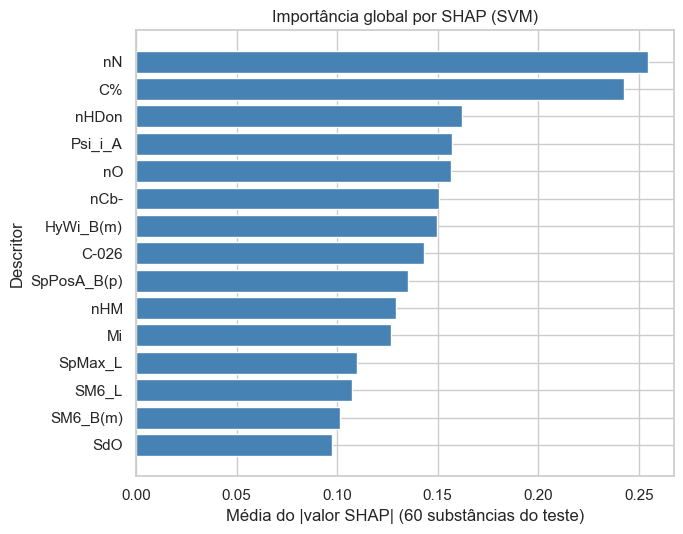

In [57]:
def preve_modelo(dados):
    """Função que o SHAP chama: recebe um array e devolve a pontuação de RB"""
    return pontuacao(campeao_modelo, pd.DataFrame(dados, columns = X_treino.columns))

fundo = shap.sample(X_treino, 40, random_state = SEMENTE_ALEATORIA)
amostra_explicada = X_teste.sample(60, random_state = SEMENTE_ALEATORIA)

explicador = shap.Explainer(preve_modelo, fundo, algorithm = "permutation", seed = SEMENTE_ALEATORIA)
valores_shap = explicador(amostra_explicada, max_evals = 300, silent = True)

importancia_shap = pd.Series(
    np.abs(valores_shap.values).mean(axis = 0), index = X_treino.columns
).sort_values(ascending = False)

top_shap = importancia_shap.head(15).iloc[::-1]
figura, eixo = plt.subplots(figsize = (7, 5.5))
eixo.barh(top_shap.index, top_shap.values, color = "steelblue")
rotula(eixo, "Média do |valor SHAP| (60 substâncias do teste)", "Descritor",
      f"Importância global por SHAP ({CAMPEAO})")
figura.tight_layout()
salva_figura(figura, "16_importancia_shap")

importancia_shap.head(10).to_frame("Média do |SHAP|").assign(
    Descrição = lambda d: d.index.map(DESCRICAO)
).round(4)

A tabela mostra que o ranking do SHAP inclui descritores que a célula anterior havia deixado mais pra trás, como `C%` (porcentagem de átomo de carbono), `nHDon` (Doadores de ligação de hidrogênio), `nCb-` (carbonos de benzeno substituídos) e `C-026`. Em comum com a *permutation importance* aparecem `nN`, `Psi_i_A`, `nO`, `SpPosA_B(p)` e `nHM`. A comparação entre as duas ferramentas é feita na última célula da seção. 

Com o gráfico plotado, vemos que, pelo SHAP, os descritores mais importantes são `nN` (0,255) e `C%` (0,242), seguidos de longe por `nHDon`, `Psi_i_A` e `nO` (todos em torno de 0,16). Dois descritores se destacam dos demais, e depois do terceiro o decaimento é gradual. Diferentemente da *permutation importance*, esta medida mostra o quanto cada descritor move a previsão da média, e não o quanto o desempenho piora sem ele. 

A célula a seguir mostra o resultado do SHAP substância por substância. Cada ponto é uma das 60 substâncias, o eixo horizontal é o valor SHAP (positivo empurra para RB e negativo para NRB), e a cor indica o valor do descritor (vermelho é alto e azul é baixo). Os descritores aparecem ordenados por importância global. Assim, o gráfico mostra a magnitude do efeito e também a sua direção, o que o gráfico de barras anterior não mostra.

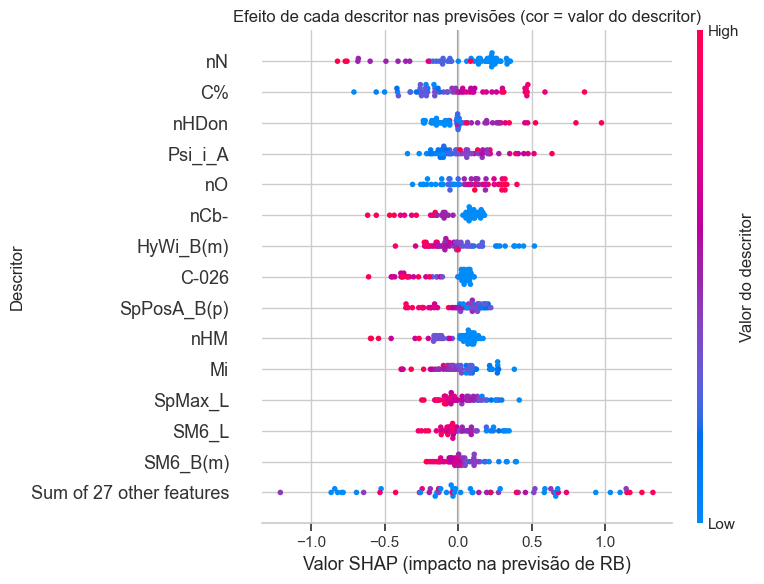

In [58]:
shap.plots.beeswarm(valores_shap, max_display = 15, show = False)
figura = plt.gcf()
figura.set_size_inches(8, 6)
figura.axes[-1].set_ylabel("Valor do descritor") 
rotula(plt.gca(), "Valor SHAP (impacto na previsão de RB)", "Descritor",
       "Efeito de cada descritor nas previsões (cor = valor do descritor)")
figura.tight_layout()
salva_figura(figura, "17_shap_beeswarm")
plt.show()

Para vários descritores a cor se separa nitidamente entre os lados do gráfico, e isso indica um efeito consistente. Valores altos de `nN`, `nCb-`, `HyWi_B(m)`, `C-026`, `SpPosA_B(p)`, `nHM`, `Mi`, `SpMax_L` e `SM6_L` empurram a previsão para NRB. Valores altos de `C%`, `nHDon`, `Psi_i_A`, `nO` e `SdO` empurram para RB. Quimicamente isso é coerente com a ideia de que anéis aromáticos substituídos, nitrogênio e átomos pesados aumentam a persistência da substância, enquanto o oxigênio favorece a degradação rápida. 

A célula a seguir tem duas partes. Na primeira, para os três descritores mais importantes pelo SHAP (`nN`, `C%` e `nHDon`), fazemos um gráfico de dispersão do valor do descritor contra seu valor SHAP. Assim vemos como o efeito muda ao longo da faixa de valores, e não apenas se ele é positivo ou negativo. A linha tracejada em zero marca onde o descritor deixa de empurrar a previsão para um lado ou para outro. Na segunda parte, comparamos os rankings da *permutation importance* e do SHAP com a correlação de Spearman e contamos quantos descritores aparecem entre os 10 primeiros de ambos. 

Correlação de Spearman entre as duas importâncias:  0.31
Descritores em comum entre os 10 primeiros de cada ferramenta: 5


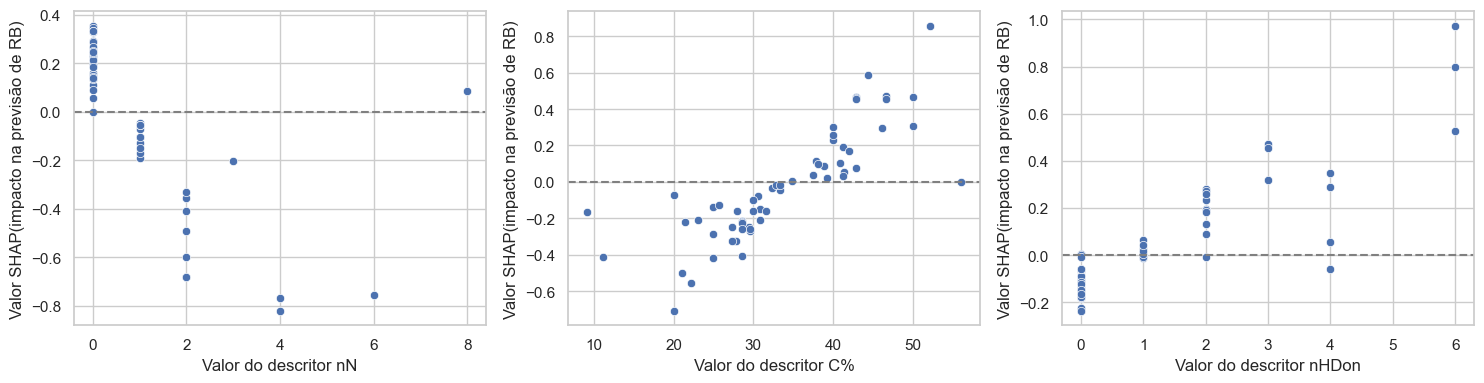

In [63]:
tres_principais = importancia_shap.index[:3]
indices_colunas = [list(X_treino.columns).index(c) for c in tres_principais]

figura, eixos = plt.subplots(1, 3, figsize = (15, 4))

for eixo, coluna, indice in zip(eixos, tres_principais, indices_colunas):
    sns.scatterplot(
        x = amostra_explicada[coluna].values, y = valores_shap.values[:, indice], ax = eixo
    )
    eixo.axhline(0, color = "gray", linestyle = "--")
    rotula(eixo, f"Valor do descritor {coluna}", "Valor SHAP (impacto na previsão de RB)")

figura.tight_layout()
salva_figura(figura, "18_shap_dependencia")

# analisando se as duas ferramentas ordenam os descritores de forma parecida
comparacao = pd.DataFrame(
    {
    "permutation importance": df_pi.set_index("Descritor")["Queda média do MCC"],
    "SHAP (média |valor|)": importancia_shap,
    }
)
rho = spearmanr(comparacao["permutation importance"], comparacao["SHAP (média |valor|)"]).statistic
print(f"Correlação de Spearman entre as duas importâncias: {rho: .2f}")

top10_pi = set(df_pi["Descritor"].head(10))
top10_shap = set(importancia_shap.index[:10])
print(f"Descritores em comum entre os 10 primeiros de cada ferramenta: {len(top10_pi & top10_shap)}")

Podemos observar que os três descritores têm efeitos claros e aproximadamente monotônicos (isto é, mantêm o mesmo sentido de variação ao longo do seu domínio):

- `nN`: substâncias sem nitrogênio têm SHAP positivo (cerca de +0,1 e +0,35), com um nitrogênio ficam levemente negativas e a partir de dois nitrogênios o efeito é fortemente negativo (de cerca de -0,2 a -0,8). Há um único ponto com `nN` = 8 e SHAP levemente positivo, uma exceção isolada, provavelmente fruto de interações com outros descritores.

- `C%`: o SHAP cresce com a porcentagem de carbono e cruza o zero por volta de 33-35%. Abaixo disso o efeito é negativo (até cerca de -0,7) e acima é positivo (até cerca de +0,85).

- `nHDon`: substâncias sem doadores de ligação de hidrogênio têm SHAP negativo (cerca de -0,1 a -0,25), com um doador o efeito é quase nulo, e com dois ou mais o efeito é positivo, chegando perto de +1 com seis doadores (salvo poucos pontos próximos de zero).


A correlação de Spearman entre os dois rankings é baixa (0,31), e só 5 dos 10 primeiros descritores são comuns. As duas ferramentas respondem a perguntas diferentes, então essa discordância não indica que uma delas esteja errada.

#### 11.2 Panorama geral do que foi observado

1. O descritor `nN` é o resultado mais robusto. Ele é o primeiro nas duas ferramentas, de modo que a *permutation importance* mostra que o desempenho cai mais ao perdê-lo, e o SHAP mostra que ele é o que mais move as previsões. O gráfico de dependência explica o mecanismo: o efeito é praticamente "tem ou não tem nitrogênio", com o SHAP passando de positivo (sem N) para fortemente negativo (dois ou mais N). Essa direção coincide com a do *beeswarm* e com a intuição química de que compostos nitrogenados tendem a ser mais persistentes.

2. As direções dos efeitos são consistentes entre os gráficos. O *beeswarm* já indicava que `nN` alto empurra para NRB, e que `C%` e `nHDon` altos empurram para RB. Os gráficos de dependência confirmam isso e mostram a forma do efeito: monotônico, com ponto de virada em torno de 33-35% de carbono, por exemplo. Em conjunto, o modelo parece ter aprendido que moléculas mais oxigenadas, com doadores de ligação de hidrogênio e mais ricas em carbono (possivelmente cadeias mais alifáticas) são mais degradáveis, enquanto nitrogênio, anéis aromáticos e átomos pesados indicam persistência.

3. As duas ferramentas discordam em parte, e há razões para isso. A correlação de Spearman de 0,31 mostra que os rankings diferem bastante. Isso ocorre por duas razões: a primeira é a correlação entre descritores, `C%`, `nCb-`, `HyWi_B(m)` e `C-026` estão no topo do SHAP, mas ficam mais abaixo na *permutation importance*, pois ao embaralhar um deles o modelo compensa com outro correlacionado e a queda do MCC dilui; a segunda é a esparsidade, `nArNO2` e `nCrt` são importantes na *permutation importance*, porque afetam bastante as poucas substâncias que os possuem, mas têm média baixa no SHAP, porque aparecem em pouquíssimas das 60 substâncias explicadas. Por isso vale olhar as duas ferramentas juntas, pois cada uma destaca um aspecto diferente do modelo.

4. Limitações: as duas análises usam poucos exemplos (215 no teste para a *permutation importance* e 60 para o SHAP), então os rankings têm incerteza, como mostram as barras de erro sobrepostas. Além disso, as explicações são associações aprendidas pelo modelo, não relações causais entre estrutura e biodegradabilidade. A interpretação química detalhada de índices topológicos como `Psi_i_A` ou `HyWi_B(m)` exige conhecimento de domínio que vai além do escopo do trabalho.

### 12. Conclusões e principais aprendizados 



**Respondendo a pergunta do projeto:** Sim, é possível prever se uma substância é rapidamente biodegradável (RB) a partir de 41 descritores moleculares com desempenho bom (MCC de cerca de 0,66 no teste) e muito acima do baseline. O melhor modelo, um SVM com kernel RBF (`C` de aproximadamente 4,85, `gamma` de aproximadamente 0,044, normalização padrão, pesos de classe balanceados e sem redução de dimensionalidade), obteve **MCC = 0,662** (IC95% de 0,555 a 0,756) e acurácia de 84,7% no teste, contra MCC = 0 e acurácia 70,7% do baseline.

| Algoritmo | MCC na CV repetida (treino) | MCC no teste |
|---|---|---|
| SVM (campeão) | 0,739 ± 0,052 | 0,662 |
| Floresta aleatória | 0,715 ± 0,048 | 0,644 |
| k-NN | 0,696 ± 0,052 | 0,641 |
| Regressão logística | 0,695 ± 0,057 | 0,656 |
| Naive Bayes | 0,564 ± 0,036 | 0,533 |
| Baseline | 0,000 | 0,000 |

**O que aprendemos:**

1. Metodologia importa tanto quanto o algoritmo. Agrupar substâncias quase redundantes no split, estratificar, deixar normalização e seleção de atributos dentro do `Pipeline`, escolher o campeão sem olhar o teste e usar o teste uma única vez são o que dá credibilidade ao número final. Mesmo assim, a checagem de distâncias não mostrou o teste mais longe do treino no split agrupado (p = 0,293), o que lembra que o agrupamento por arredondamento é uma proteção parcial contra vizinhos quase redundantes.

2. Métrica certa. Com classes 1:2, a acurácia do baseline (65% na CV do treino e 71% no teste, que tem menos RB) enganaria; o MCC é 0 para ele e só é alto quando o modelo acerta nas duas classes.

3. Hiperparâmetros: ganho real, mas desigual. Cada algoritmo foi testado com 100 conjuntos de hiperparâmetros (o primeiro é a configuração padrão). O `optuna` melhorou de 0,010 a 0,047 em relação a configuração padrão, e o maior ganho foi do Naive Bayes, que parte de um desempenho bem mais baixo. Os hiperparâmetros de regularização (`C`, vizinhos, folha mínima) foram os que mais importaram. O ganho medido nos folds da otimização é otimista: na CV o melhor MCC caiu em quatro dos cinco algoritmos (só o SVM manteve o valor).

4. Redução de dimensionalidade quase nunca foi necessária. Com 41 atributos e 840 exemplos, "nenhuma redução" foi a melhor ou empatou (diferença de no máximo 0,001) para todos os cinco algoritmos: k-NN, regressão logística, SVM, Naive Bayes e floresta aleatória. O PCA prejudicou o Naive Bayes e o k-NN.

5. Os melhores algoritmos são difíceis de distinguir. SVM, regressão logística, floresta aleatória e k-NN têm MCC de teste entre 0,64 e 0,66 com intervalos de confiança sobrepostos e AUC-ROC em torno de 0,92. Com 215 exemplos de teste, só é seguro dizer que esses quatro formam um grupo melhor que o Naive Bayes (diferença clara na CV repetida e em todas as métricas do teste). O SVM foi escolhido pela CV repetida, mas no teste ele supera a regressão logística por apenas 0,006 de MCC; se simplicidade e interpretabilidade forem prioridade, a regressão logística é uma alternativa igualmente defensável.

6. Naive Bayes é o pior. Isso combina com a alta correlação entre os descritores. Ele classifica RB em excesso (revocação de 0,92, precisão de 0,53).

7. Onde o campeão erra. O SVM acerta 84% das substâncias NRB e 86% das RB, mas o erro mais frequente é classificar como RB uma substância que é NRB (24 casos, contra 9 no sentido oposto), o que limita a precisão a 69%. No contexto ambiental esse é o erro mais custoso, porque uma substância persistente seria tratada como biodegradável.

8. Explicação. Átomos de nitrogênio (`nN`), carbonos aromáticos (`nCb-`) e átomos pesados (`nHM`) empurram para NRB, enquanto átomos de oxigênio (`nO`), maior porcentagem de carbono (`C%`) e mais doadores de ligação de hidrogênio (`nHDon`) empurram para RB, em linha com a intuição química geral, mas apenas como associações do modelo. O efeito de `nN` é o mais robusto: ele aparece em primeiro lugar nas duas ferramentas, e o gráfico de dependência mostra que o SHAP passa de positivo (sem nitrogênio) para fortemente negativo (dois ou mais). A *permutation importance* e o SHAP concordam pouco no ranking completo (Spearman de 0,31), em parte por causa da correlação entre os descritores e da esparsidade de alguns deles.

**Limitações encontradas:**

1. O teste tem só 215 substâncias e uma proporção de RB diferente da do treino (29,3% contra 34,9%); o IC95% do MCC tem cerca de ±0,10 de meia-largura e o MCC no teste ficou abaixo do da CV repetida para todos os modelos.

2. A otimização usou uma única partição de folds; a CV repetida mitiga, mas não elimina, o viés de seleção (uma validação cruzada aninhada [13] seria o passo seguinte).

3. O agrupamento de substâncias parecidas é uma heurística (arredondamento dos descritores), e o teste de distâncias teve pouco poder em 41 dimensões e não mostrou o teste mais longe do treino.

4. O modelo só deve ser aplicado a substâncias parecidas com as do conjunto de dados (domínio de aplicabilidade), e as previsões do SVM não são probabilidades calibradas.

5. As explicações (*permutation importance* e SHAP) usam poucos exemplos (215 e 60 substâncias, respectivamente) e sofrem com descritores correlacionados; descrevem o que o modelo aprendeu, não relações causais entre estrutura e biodegradabilidade.

**Próximos passos possíveis:**

Validação cruzada aninhada; calibração de probabilidades e ajuste do limiar de decisão conforme o custo de cada tipo de erro (por exemplo, penalizar mais classificar como RB uma substância persistente, que foi o erro mais frequente do campeão); comparar outros algoritmos (como *gradient boosting* [7] e redes neurais); e usar descritores adicionais ou impressões digitais moleculares.

### 13. Lore da disciplina 

Com as notícias do ataque de um Dragão Lendário e o pedido do Rei Milu Iluminarius MLVI, a casa Merith foi uma das primeiras a levantar suas bandeiras e enviar uma carta para a capital real mostrando seu apoio. 

A casa Merith é uma das casas costeiras e uma das mais ricas do reino de Lumi, conseguindo suas riquezas através da venda de pedras marinhas preciosas e frutos do mar. Seu brasão e seus ideais unem a beleza e graça das pérolas e corais com a impiedade dos mares. 

Quando a carta chegou à capital, o Rei se surpreendeu com as palavras do chefe da família Merith. Em sua mensagem ele afirmava que faria o que fosse possível para a proteção do reino, de modo que estaria, nesse momento, protegendo e patrulhando a parte costeira do reino, mas iria para a capital real se necessário. Ao final de sua carta, está o lema da casa Merith, mostrando seu apoio à causa: "Riqueza nas profundezas, honra na superfície!"

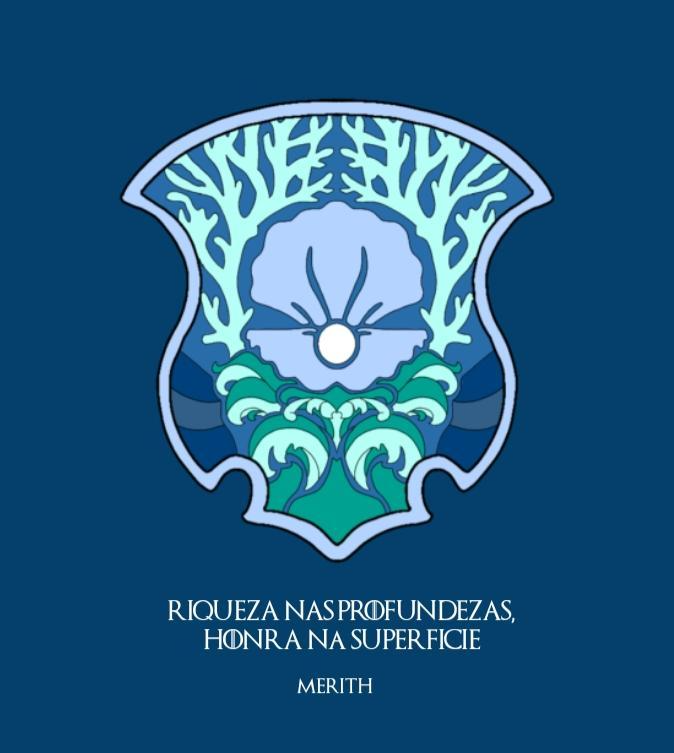

### Descrição do uso de IA 

Para a criação do trabalho, foi usada a Inteligência Artificial Claude (Anthropic) através da interface de chat.

A ferramenta foi utilizada para:

1. Auxílio na escolha do conjunto de dados. Enviei o enunciado e pedi sugestões de conjuntos de dados que seguissem os critérios do trabalho e pudessem ser explorados devidamente com os métodos e ferramentas do enunciado.

2. Ajuda para a coletânea de referências. Pedi sugestões de leituras que pudessem auxiliar a construção do trabalho.

3. Auxílio para a construção e correção de células de código. Em muitas ocasiões a IA me ajudou a construir ou consertar células de código, desde células de funções até a células de plotagem de gráficos.

4. Discussão de pontos teóricos e retirada de dúvidas. Em certos momentos, alguns pontos teóricos não foram muito claros durante os meus estudos, de modo que usei a IA para sanar essas dificuldades.

5. Ajuda para indicar qual o melhor "próximo passo". Em certos momentos eu não sabia qual seria a melhor coisa a se fazer para dar continuidade ao projeto, de modo que o Claude me auxiliou dando sugestões do que poderia ser feito a seguir.

6. Revisão do notebook. Ao finalizar o projeto, enviei o notebook ao Claude para que ele revisasse, procurando erros, incongruências e pontos que poderiam ser melhorados ou corrigidos.

### Referências

[1] MANSOURI, K.; RINGSTED, T.; BALLABIO, D.; TODESCHINI, R.; CONSONNI, V. Quantitative Structure-Activity Relationship models for ready biodegradability of chemicals. *Journal of Chemical Information and Modeling*, v. 53, n. 4, p. 867-878, 2013. Conjunto de dados: *QSAR biodegradation*, UCI Machine Learning Repository (licença CC BY 4.0). Disponível em: https://archive.ics.uci.edu/dataset/254/qsar+biodegradation.

[2] CHICCO, D.; JURMAN, G. The advantages of the Matthews correlation coefficient (MCC) over F1 score and accuracy in binary classification evaluation. *BMC Genomics*, v. 21, art. 6, 2020.

[3] MATTHEWS, B. W. Comparison of the predicted and observed secondary structure of T4 phage lysozyme. *Biochimica et Biophysica Acta*, v. 405, n. 2, p. 442-451, 1975.

[4] AKIBA, T.; SANO, S.; YANASE, T.; OHTA, T.; KOYAMA, M. Optuna: a next-generation hyperparameter optimization framework. In: *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining*, 2019. Documentação: https://optuna.readthedocs.io.

[5] BERGSTRA, J.; BARDENET, R.; BENGIO, Y.; KÉGL, B. Algorithms for hyper-parameter optimization. In: *Advances in Neural Information Processing Systems 24 (NIPS 2011)*, 2011.

[6] PEDREGOSA, F. et al. Scikit-learn: machine learning in Python. *Journal of Machine Learning Research*, v. 12, p. 2825-2830, 2011. Documentação: https://scikit-learn.org.

[7] CHEN, T.; GUESTRIN, C. XGBoost: a scalable tree boosting system. In: *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, p. 785-794, 2016.

[8] LUNDBERG, S. M.; LEE, S.-I. A unified approach to interpreting model predictions. In: *Advances in Neural Information Processing Systems 30 (NIPS 2017)*, 2017.

[9] BREIMAN, L. Random forests. *Machine Learning*, v. 45, n. 1, p. 5-32, 2001.

[10] CASSAR, D. R. *Notebooks de aula da disciplina ATP-203 (Aprendizado de Máquina)*: tratamento de dados com pandas; k-NN e métricas; divisão de dados em treino e teste; modelo linear e baseline; árvore de decisão e floresta aleatória; classificação binária; validação cruzada e otimização de hiperparâmetros; vazamento de dados; dados sintéticos e pipeline; otimização de hiperparâmetros com optuna; redução de dimensionalidade com PCA; seleção de atributos. Ilum Escola de Ciência, 2026.

[11] CORTES, C.; VAPNIK, V. Support-vector networks. *Machine Learning*, v. 20, n. 3, p. 273-297, 1995.

[12] KAUFMAN, S.; ROSSET, S.; PERLICH, C.; STITELMAN, O. Leakage in data mining: formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, v. 6, n. 4, art. 15, 2012.

[13] VARMA, S.; SIMON, R. Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics*, v. 7, art. 91, 2006.

[14] GUYON, I.; WESTON, J.; BARNHILL, S.; VAPNIK, V. Gene selection for cancer classification using support vector machines. *Machine Learning*, v. 46, p. 389-422, 2002.

[15] HASTIE, T.; TIBSHIRANI, R.; FRIEDMAN, J. *The Elements of Statistical Learning*. 2. ed. Nova York: Springer, 2009.

[16] COVER, T.; HART, P. Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, v. 13, n. 1, p. 21-27, 1967.

[17] EFRON, B.; TIBSHIRANI, R. J. *An Introduction to the Bootstrap*. Nova York: Chapman & Hall, 1993.